In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson
import pandas as pd
import seaborn as sns

from IPython.display import set_matplotlib_formats
%config InlineBackend.figure_formats = ['svg', 'pdf']

np.set_printoptions(precision=4)

## Setting up dynamics

In [2]:
# Define the starting value for testing
haplo_freq = np.array([0.5, 0.5, 0, 0])

# Define model parameters
epi_vec = np.array([0.021, 0.042, 0.084])     # epistasis, g1, g2, g4
overdom_vec = np.array([0.02, 0.02]) # overdominance (as alpha, beta)
mig_vec = np.array([0.02, 0.05])     # migration
rec = 0.01                      # recombination

# Define selection matrix for all 16 possible combinations of gametes (from mom and dad)
selection_mat = np.array([
    [1, 1 + overdom_vec[0], 1 + overdom_vec[1], (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0])],
    [1 + overdom_vec[0], 1, (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), (1 + overdom_vec[0]) * (1 - epi_vec[1])],
    [1 + overdom_vec[1], (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), 1, (1 + overdom_vec[1]) * (1 - epi_vec[1])],
    [(1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), (1 + overdom_vec[0]) * (1 - epi_vec[1]), (1 + overdom_vec[1]) * (1 - epi_vec[1]), 1 - epi_vec[2]]
])

# Print the selection matrix
print("Selection Matrix:")
print(selection_mat)

# Migration step (if zygotes arrive)
haplo_freq = haplo_freq * (1 - np.sum(mig_vec)) + np.array([0, mig_vec[0], mig_vec[1], 0])
print("Freq after migration")
print(haplo_freq)


# Random mating creates genotypes
geno_mat = np.outer(haplo_freq, haplo_freq)

# Selection step: multiply with selection table and renormalize by mean fitness
selection = selection_mat * geno_mat
fit_mean = np.sum(selection)
geno_mat = selection / fit_mean

# Print genotype frequency matrix
print("Genotype Frequency Matrix after Selection:")
print(geno_mat)
print("Sum of Genotype Frequencies:", np.sum(geno_mat))

# Migration step. Not sure if migrants are removed from all genotypes.
geno_mat *= (1 - np.sum(mig_vec))
geno_mat[1, 1] += mig_vec[0]
geno_mat[2, 2] += mig_vec[1]

# Return from genotype level to gametes/haplotypes with recombination
haplo_freq = np.array([
    np.sum(geno_mat[0, :] / 2 + geno_mat[:, 0] / 2) - rec * (geno_mat[0, 3] + geno_mat[3, 0]) / 2 + rec * (geno_mat[1, 2] + geno_mat[2, 1]) / 2,
    np.sum(geno_mat[1, :] / 2 + geno_mat[:, 1] / 2) - rec * (geno_mat[1, 2] + geno_mat[2, 1]) / 2 + rec * (geno_mat[3, 0] + geno_mat[0, 3]) / 2,
    np.sum(geno_mat[2, :] / 2 + geno_mat[:, 2] / 2) - rec * (geno_mat[1, 2] + geno_mat[2, 1]) / 2 + rec * (geno_mat[3, 0] + geno_mat[0, 3]) / 2,
    np.sum(geno_mat[3, :] / 2 + geno_mat[:, 3] / 2) - rec * (geno_mat[0, 3] + geno_mat[3, 0]) / 2 + rec * (geno_mat[1, 2] + geno_mat[2, 1]) / 2
])

# Print the haplotype frequencies after recombination
#print("Haplotype Frequencies after Recombination:")
#print(haplo_freq)
#print("Sum of Haplotype Frequencies:", np.sum(haplo_freq))


Selection Matrix:
[[1.     1.02   1.02   1.0186]
 [1.02   1.     1.0186 0.9772]
 [1.02   1.0186 1.     0.9772]
 [1.0186 0.9772 0.9772 0.916 ]]
Freq after migration
[0.465 0.485 0.05  0.   ]
Genotype Frequency Matrix after Selection:
[[0.2139 0.2276 0.0235 0.    ]
 [0.2276 0.2327 0.0244 0.    ]
 [0.0235 0.0244 0.0025 0.    ]
 [0.     0.     0.     0.    ]]
Sum of Genotype Frequencies: 1.0


## 2 Locus

### One generation

In [3]:
def simulate_one_gen(haplo_freq, selection_mat, mig_vec, rec):
    # Life cycle: 1. Parental gametes to newborn genotypes w random mating; 2. Selection, 3. Migration, 4. Recombination
    
    # Determine genotype frequencies assuming random mating for all 16 genotypes
    geno_mat = np.outer(haplo_freq, haplo_freq)

    # Selection step
    selection = selection_mat * geno_mat
    fit_mean = np.sum(selection)
    geno_mat = selection / fit_mean

    # Migration step (if adult genotypes arrive after selection) -> Should the negative term apply to all?
    geno_mat *= (1 - np.sum(mig_vec))
    geno_mat[1, 1] += mig_vec[0]
    geno_mat[2, 2] += mig_vec[1]

    # Return to gametes/haplotypes with recombination
    haplo_freq = np.array([
        np.sum(geno_mat[0, :] / 2 + geno_mat[:, 0] / 2) - rec * (geno_mat[0, 3] + geno_mat[3, 0]) / 2 + rec * (geno_mat[1, 2] + geno_mat[2, 1]) / 2,
        np.sum(geno_mat[1, :] / 2 + geno_mat[:, 1] / 2) - rec * (geno_mat[1, 2] + geno_mat[2, 1]) / 2 + rec * (geno_mat[3, 0] + geno_mat[0, 3]) / 2,
        np.sum(geno_mat[2, :] / 2 + geno_mat[:, 2] / 2) - rec * (geno_mat[1, 2] + geno_mat[2, 1]) / 2 + rec * (geno_mat[3, 0] + geno_mat[0, 3]) / 2,
        np.sum(geno_mat[3, :] / 2 + geno_mat[:, 3] / 2) - rec * (geno_mat[0, 3] + geno_mat[3, 0]) / 2 + rec * (geno_mat[1, 2] + geno_mat[2, 1]) / 2
    ])

    return haplo_freq

# Test the function
print(simulate_one_gen(np.array([0, 0.5, 0.5, 0]), selection_mat, mig_vec, rec))


[0.0023 0.4827 0.5127 0.0023]


In [4]:
def simulate_one_gen_stoch(haplo_freq, sel_matrix, mig_vec, popsize, rec_rate):
    # Convert migration vector from rate to absolute number of migrants
    migno_vec = mig_vec * popsize

    # Determine genotype frequencies assuming random mating
    geno_mat = np.outer(haplo_freq, haplo_freq) # Get all 16 genotype frequencies

    # Selection step
    selection = sel_matrix * geno_mat 
    fit_mean = np.sum(selection)
    geno_mat = selection / fit_mean

    # Determine number of migrants that arrive this generation
    migrants = [poisson.rvs(migno_vec[0]), poisson.rvs(migno_vec[1])]

    # Determine population composition after selection (leaving space for migrants)
    flat_genfreq = geno_mat.flatten()
    
    popsize_matrix = np.reshape(np.random.multinomial(popsize - sum(migrants), flat_genfreq), (4, 4))
        
    # Introduce migrant genotypes
    popsize_matrix[1, 1] += migrants[0]
    popsize_matrix[2, 2] += migrants[1]

    # Return to genotype frequencies
    geno_mat = popsize_matrix / np.sum(popsize_matrix)

    # Return to gametes/haplotypes with recombination
    haplo_freq = np.array([
        np.sum(geno_mat[0, :] / 2 + geno_mat[:, 0] / 2) - rec_rate * (geno_mat[0, 3] + geno_mat[3, 0]) / 2 + rec_rate * (geno_mat[1, 2] + geno_mat[2, 1]) / 2,
        np.sum(geno_mat[1, :] / 2 + geno_mat[:, 1] / 2) - rec_rate * (geno_mat[1, 2] + geno_mat[2, 1]) / 2 + rec_rate * (geno_mat[3, 0] + geno_mat[0, 3]) / 2,
        np.sum(geno_mat[2, :] / 2 + geno_mat[:, 2] / 2) - rec_rate * (geno_mat[1, 2] + geno_mat[2, 1]) / 2 + rec_rate * (geno_mat[3, 0] + geno_mat[0, 3]) / 2,
        np.sum(geno_mat[3, :] / 2 + geno_mat[:, 3] / 2) - rec_rate * (geno_mat[0, 3] + geno_mat[3, 0]) / 2 + rec_rate * (geno_mat[1, 2] + geno_mat[2, 1]) / 2
    ])

    return haplo_freq

# Example parameters
sel_matrix = np.array([[1, 1, 1, 1], [1, 1, 1, 1], [1, 1, 1, 1], [1, 1, 1, 1]])  # Replace with actual selection matrix
mig_vec = np.array([0.01, 0.01])  # Replace with actual migration vector
popsize = 10000
rec_rate = 0.01  # Replace with actual recombination rate

# Test the function
initial_haplo_freq = np.array([0.885, 0.075, 0.030, 0.010])
print(simulate_one_gen_stoch(initial_haplo_freq, selection_mat, mig_vec, popsize, rec_rate))


[0.8611 0.0873 0.0407 0.0109]


### Simulating a population

In [5]:
def haplo_to_allele(haplotypes):
    return [haplotypes[1]+haplotypes[3], haplotypes[2]+haplotypes[3], haplotypes[0]*haplotypes[3]-haplotypes[1]*haplotypes[2]]

In [6]:
#Rewriting function with population
def simulate_pop(haplo_freq0, t_max, sel_matrix, mig_vec, rec_rate, popsize=0):
    # Create the matrix to store results
    pop_vector = [haplo_freq0]
    pop_new = haplo_freq0

    # Run the simulation until generation t_max
    for i in range(1, t_max + 1):
        if popsize==0: # If the parameter is 0, deterministic
            # Update the population one generation later
            pop_new = simulate_one_gen(pop_new, sel_matrix, mig_vec, rec_rate)
        else:
            pop_new = simulate_one_gen_stoch(pop_new, sel_matrix, mig_vec, popsize, rec_rate)
        pop_vector.append(pop_new)
        # Stop simulation early if allele frequency change is very small
        if np.sum(np.abs(pop_vector[i] - pop_vector[i - 1])) < 0.000001:
            break

    # Convert the result list to a numpy array
    pop_vector = np.array(pop_vector)
    
    # Define row and column names (as labels in the output)
    return pop_vector


#### Test 

In [7]:
# Define params 
popsize = 10000
migno_vec = mig_vec*popsize #Migration as an average of migrants.

[[0.5535 0.1899 0.1929 0.0637]]


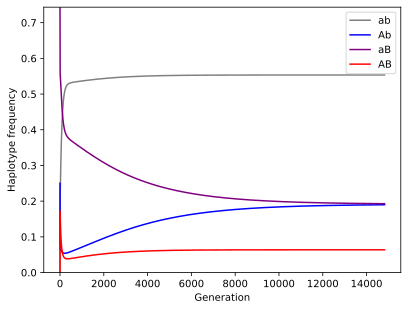

In [8]:
# Test deterministic and plot the result

# Define the starting value for testing
haplo_freq = np.array([0, 0.25, 0.75, 0])

# Define model parameters
epi_vec = np.array([0.019, 0.038, 0.076])     # epistasis, g1, g2, g4
overdom_vec = np.array([0.02, 0.02]) # overdominance (as alpha, beta)
mig_vec = np.array([0, 0])     # migration
rec = 0.5                      # recombination

# Define selection matrix for all 16 possible combinations of gametes (from mom and dad)
selection_mat = np.array([
    [1, 1 + overdom_vec[0], 1 + overdom_vec[1], (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0])],
    [1 + overdom_vec[0], 1, (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), (1 + overdom_vec[0]) * (1 - epi_vec[1])],
    [1 + overdom_vec[1], (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), 1, (1 + overdom_vec[1]) * (1 - epi_vec[1])],
    [(1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), (1 + overdom_vec[0]) * (1 - epi_vec[1]), (1 + overdom_vec[1]) * (1 - epi_vec[1]), 1 - epi_vec[2]]
])

max_gen = 30000

output = simulate_pop(haplo_freq, max_gen, selection_mat, mig_vec, rec)

# Show the last few lines of the data table
print(output[-1:])

# Plot the output
x_range = np.arange(len(output))
plt.plot(x_range, output[:, 0], label="ab", color="gray")
plt.plot(x_range, output[:, 1], label="Ab", color="blue")
plt.plot(x_range, output[:, 2], label="aB", color="purple")
plt.plot(x_range, output[:, 3], label="AB", color="red")
plt.ylim(0, np.max(output[:, 0] + output[:, 1]))
plt.xlabel("Generation")
plt.ylabel("Haplotype frequency")
plt.legend()
plt.show()

[[1.     1.02   1.02   1.0206]
 [1.02   1.     1.0206 0.9812]
 [1.02   1.0206 1.     0.9812]
 [1.0206 0.9812 0.9812 0.924 ]]
[0.8835 0.     0.1165 0.    ]


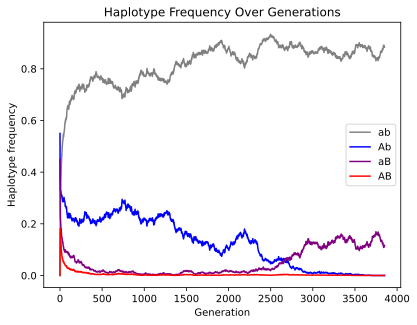

In [9]:
# Test stochastic
# Test parameters, no selection, no migration
sel_matrix = np.array([[1, 1, 1, 1], [1, 1, 1, 1], [1, 1, 1, 1], [1, 1, 1, 0]])  # Replace with actual selection matrix
mig_vec = np.array([0.0, 0.0])  # Replace with actual migration vector
popsize = 10000
rec_rate = 0.5  # Replace with actual recombination rate
t_max = 10000

# Run the simulation
initial_haplo_freq = np.array([0, 0.55, 0.45, 0])
output = simulate_pop(initial_haplo_freq, t_max, sel_matrix, mig_vec, rec_rate, popsize=popsize)
print(selection_mat)
# Display the last few lines of the output
print(output[-1])

# Plotting the result
x_range = np.arange(0, len(output))
plt.plot(x_range, output[:, 0], label='ab', color='gray')
plt.plot(x_range, output[:, 1], label='Ab', color='blue')
plt.plot(x_range, output[:, 2], label='aB', color='purple')
plt.plot(x_range, output[:, 3], label='AB', color='red')
plt.xlabel('Generation')
plt.ylabel('Haplotype frequency')
plt.title('Haplotype Frequency Over Generations')
plt.legend()
plt.show()

## 3 locus

First, setting up dynamics

### One generation

In [10]:
#With haplotype frequencies:
                     # abc,  Abc, aBc, ABc, abC,  AbC,  aBC,  ABC 
haplo_freq = np.array([0.00, 0.5, 0.0, 0.0, 0.00, 0.00, 0.5, 0.00])

# Define model parameters
epi_vec = np.array([0.021, 0.042, 0.084])     # epistasis, g1, g2, g4
overdom_vec = np.array([0.02, 0.02]) # overdominance (as alpha, beta)
mig_vec = np.array([0.01, 0.01])     # migration
rec = np.array([0.002,0.003])          # recombination between ab & bc
r_ab = rec[0]
r_bc = rec[1]


selection_mat = np.array([
    [1, 1 + overdom_vec[0], 1 + overdom_vec[1], (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0])],
    [1 + overdom_vec[0], 1, (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), (1 + overdom_vec[0]) * (1 - epi_vec[1])],
    [1 + overdom_vec[1], (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), 1, (1 + overdom_vec[1]) * (1 - epi_vec[1])],
    [(1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), (1 + overdom_vec[0]) * (1 - epi_vec[1]), (1 + overdom_vec[1]) * (1 - epi_vec[1]), 1 - epi_vec[2]]
])

sum(haplo_freq)

1.0

In [11]:
# We repeat the selection matrix on the X and Y axis
selection_mat_3 = np.tile(selection_mat,(2,2))
# selection_mat_3 = np.ones((8,8)) #Neutral

selection_mat_df = pd.DataFrame(data= selection_mat_3,
                                index = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"],
                                columns = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"])
selection_mat_df

,abc,Abc,aBc,ABc,abC,AbC,aBC,ABC
abc,1.000000,1.020000,1.020000,1.018552,1.000000,1.020000,1.020000,1.018552
Abc,1.020000,1.000000,1.018552,0.977160,1.020000,1.000000,1.018552,0.977160
aBc,1.020000,1.018552,1.000000,0.977160,1.020000,1.018552,1.000000,0.977160
ABc,1.018552,0.977160,0.977160,0.916000,1.018552,0.977160,0.977160,0.916000
abC,1.000000,1.020000,1.020000,1.018552,1.000000,1.020000,1.020000,1.018552
AbC,1.020000,1.000000,1.018552,0.977160,1.020000,1.000000,1.018552,0.977160
aBC,1.020000,1.018552,1.000000,0.977160,1.020000,1.018552,1.000000,0.977160
ABC,1.018552,0.977160,0.977160,0.916000,1.018552,0.977160,0.977160,0.916000


In [12]:
#Migration of Abc and aBC only 
# haplo_freq = haplo_freq * (1 - np.sum(mig_vec)) + np.array([0, mig_vec[0], 0, 0, 0, 0, mig_vec[1], 0])

In [13]:
# Random mating to create genotypes
geno_mat = np.outer(haplo_freq, haplo_freq)
# Selection step: multiply with selection table and renormalize by mean fitness
selection = selection_mat_3 * geno_mat
fit_mean = np.sum(selection)
geno_mat = selection / fit_mean

In [14]:
# Print genotype frequency matrix
print("Genotype Frequency Matrix after Selection:")
print("Genotype Frequency Matrix after Selection:")
print(geno_mat)
print("Sum of Genotype Frequencies:", np.sum(geno_mat))

Genotype Frequency Matrix after Selection:
Genotype Frequency Matrix after Selection:
[[0.     0.     0.     0.     0.     0.     0.     0.    ]
 [0.     0.2477 0.     0.     0.     0.     0.2523 0.    ]
 [0.     0.     0.     0.     0.     0.     0.     0.    ]
 [0.     0.     0.     0.     0.     0.     0.     0.    ]
 [0.     0.     0.     0.     0.     0.     0.     0.    ]
 [0.     0.     0.     0.     0.     0.     0.     0.    ]
 [0.     0.2523 0.     0.     0.     0.     0.2477 0.    ]
 [0.     0.     0.     0.     0.     0.     0.     0.    ]]
Sum of Genotype Frequencies: 1.0


In [15]:
# Migration step. For Abc and aBC only 
geno_mat *= (1 - np.sum(mig_vec))
geno_mat[1, 1] += mig_vec[0]
geno_mat[6, 6] += mig_vec[1]

In [16]:
# Setting up all recombination terms
rec_vec = np.zeros(8)
## abc
# Loses
rec_vec[0] = (-r_bc*(geno_mat[0,6] + geno_mat[6,0])/2         # abc/aBC -> abC + aBc
- r_bc*(1-r_ab)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC -> abC + Abc
- r_ab*(1-r_bc)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC -> abC + Abc
- r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # abc/ABc -> Abc + aBc
- (r_ab + r_bc - r_ab*r_bc)*(geno_mat[0,7] + geno_mat[7,0])/2 # abc/ABC -> aBc + AbC lose when rec a, c and b
# Gains
+ r_ab*(geno_mat[1,2] + geno_mat[2,1])/2                      # Abc/aBc -> ABc + abc
+ r_ab*(1-r_bc)*(geno_mat[1,6] + geno_mat[6,1])/2             # Abc/aBC -> ABC + abc
+ r_bc*(geno_mat[2,4] + geno_mat[4,2])/2                      # abC/aBc -> abc + aBC
+ r_bc*(1-r_ab)*(geno_mat[3,4] + geno_mat[4,3])/2             # abC/ABc -> abc + ABC
+ r_bc*(1-r_ab)*(geno_mat[1,4] + geno_mat[4,1])/2             # abC/Abc -> abc + AbC
+ r_ab*(1-r_bc)*(geno_mat[1,4] + geno_mat[4,1])/2             # abC/Abc -> abc + AbC
+ r_ab*r_bc*(geno_mat[2,5] + geno_mat[5,2])/2)                # aBc/AbC -> abc + ABC


## Abc
# Loses
rec_vec[1] = (-r_bc*(geno_mat[1,7] + geno_mat[7,1])/2         # Abc/ABC -> AbC + ABc
- r_bc*(1-r_ab)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC -> AbC + abc
- r_ab*(1-r_bc)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC -> AbC + abc
- r_ab*(geno_mat[1,2] + geno_mat[2,1])/2                      # Abc/aBc -> ABc + abc
- (r_ab + r_bc - r_ab*r_bc)*(geno_mat[1,6] + geno_mat[6,1])/2 # Abc/aBC lose when rec a, c and b
# Gains 
+ r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # abc/ABc
+ r_ab*(1-r_bc)*(geno_mat[0,7] + geno_mat[7,0])/2             # abc/ABC 
+ r_bc*(geno_mat[5,3] + geno_mat[3,5])/2                      # AbC/ABc
+ r_bc*(1-r_ab)*(geno_mat[2,5] + geno_mat[5,2])/2             # AbC/aBc
+ r_bc*(1-r_ab)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
+ r_ab*(1-r_bc)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
+ r_ab*r_bc*(geno_mat[3,4] + geno_mat[4,3])/2)                # ABc/abC


## aBc
# Loses
rec_vec[2] = (-r_bc*(geno_mat[2,4] + geno_mat[4,2])/2         # aBc/abC
- r_bc*(1-r_ab)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
- r_ab*(1-r_bc)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
- r_ab*(geno_mat[2,1] + geno_mat[1,2])/2                      # aBc/Abc
- (r_ab + r_bc - r_ab*r_bc)*(geno_mat[2,5] + geno_mat[5,2])/2 # aBc/AbC lose when rec a, c and b
# Gains 
+ r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # ABc/abc
+ r_ab*(1-r_bc)*(geno_mat[3,4] + geno_mat[4,3])/2             # ABc/abC 
+ r_bc*(geno_mat[6,0] + geno_mat[0,6])/2                      # aBC/abc
+ r_bc*(1-r_ab)*(geno_mat[6,1] + geno_mat[1,6])/2             # aBC/Abc
+ r_bc*(1-r_ab)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc
+ r_ab*(1-r_bc)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc
+ r_ab*r_bc*(geno_mat[0,7] + geno_mat[7,0])/2)                # abc/ABC

## ABc
# Loses
rec_vec[3] = (-r_bc*(geno_mat[3,5] + geno_mat[5,3])/2         # ABc/AbC
- r_bc*(1-r_ab)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
- r_ab*(1-r_bc)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
- r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # ABc/abc
- (r_ab + r_bc - r_ab*r_bc)*(geno_mat[3,4] + geno_mat[4,3])/2 # ABc/abC lose when rec a, c and b
# Gains
+ r_ab*(geno_mat[1,2] + geno_mat[2,1])/2                      # aBc/Abc
+ r_ab*(1-r_bc)*(geno_mat[2,5] + geno_mat[5,2])/2             # aBc/AbC
+ r_bc*(geno_mat[7,1] + geno_mat[1,7])/2                      # ABC/Abc
+ r_bc*(1-r_ab)*(geno_mat[7,0] + geno_mat[0,7])/2             # ABC/abc
+ r_bc*(1-r_ab)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc
+ r_ab*(1-r_bc)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc
+ r_ab*r_bc*(geno_mat[1,6] + geno_mat[6,1])/2)                # Abc/aBC

## abC
# Loses
rec_vec[4] = (-r_bc*(geno_mat[4,2] + geno_mat[2,4])/2         # abC/aBc
- r_bc*(1-r_ab)*(geno_mat[4,1] + geno_mat[1,4])/2             # abC/Abc
- r_ab*(1-r_bc)*(geno_mat[4,1] + geno_mat[1,4])/2             # abC/Abc
- r_ab*(geno_mat[4,7] + geno_mat[7,4])/2                      # abC/ABC
- (r_ab + r_bc - r_ab*r_bc)*(geno_mat[4,3] + geno_mat[3,4])/2 # abC/ABc lose when rec a, c and b
# Gains
+ r_ab*(geno_mat[5,6] + geno_mat[6,5])/2                      # AbC/aBC
+ r_ab*(1-r_bc)*(geno_mat[5,2] + geno_mat[2,5])/2             # AbC/aBc
+ r_bc*(geno_mat[0,6] + geno_mat[6,0])/2                      # abc/aBC
+ r_bc*(1-r_ab)*(geno_mat[0,7] + geno_mat[7,0])/2             # abc/ABC
+ r_bc*(1-r_ab)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
+ r_ab*(1-r_bc)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
+ r_ab*r_bc*(geno_mat[6,1] + geno_mat[1,6])/2)                # aBC/Abc

## AbC
# Loses
rec_vec[5] = (-r_bc*(geno_mat[5,3] + geno_mat[3,5])/2         # AbC/ABc switch b and c
- r_bc*(1-r_ab)*(geno_mat[5,0] + geno_mat[0,5])/2             # AbC/abc switch a and c
- r_ab*(1-r_bc)*(geno_mat[5,0] + geno_mat[0,5])/2             # AbC/abc "
- r_ab*(geno_mat[5,6] + geno_mat[6,5])/2                      # AbC/aBC Switch a and b
- (r_ab + r_bc - r_ab*r_bc)*(geno_mat[5,2] + geno_mat[2,5])/2 # AbC/aBc lose when rec a, c and b
# Gains
+ r_ab*(geno_mat[4,7] + geno_mat[7,4])/2                      # abC/ABC
+ r_ab*(1-r_bc)*(geno_mat[4,3] + geno_mat[3,4])/2             # abC/ABc
+ r_bc*(geno_mat[1,7] + geno_mat[7,1])/2                      # Abc/ABC
+ r_bc*(1-r_ab)*(geno_mat[1,6] + geno_mat[6,1])/2             # Abc/aBC
+ r_bc*(1-r_ab)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC
+ r_ab*(1-r_bc)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC
+ r_ab*r_bc*(geno_mat[7,0] + geno_mat[0,7])/2)                # ABC/abc


## aBC
# Loses
rec_vec[6] = (-r_bc*(geno_mat[6,0] + geno_mat[0,6])/2         # aBC/abc switch b and c
- r_bc*(1-r_ab)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc switch a and c
- r_ab*(1-r_bc)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc "
- r_ab*(geno_mat[6,5] + geno_mat[5,6])/2                      # aBC/AbC Switch a and b
- (r_ab + r_bc - r_ab*r_bc)*(geno_mat[6,1] + geno_mat[1,6])/2 # aBC/Abc lose when rec a, c and b
# Gains
+ r_ab*(geno_mat[7,4] + geno_mat[4,7])/2                      # ABC/abC
+ r_ab*(1-r_bc)*(geno_mat[7,0] + geno_mat[0,7])/2             # ABC/abc
+ r_bc*(geno_mat[2,4] + geno_mat[4,2])/2                      # aBc/abC
+ r_bc*(1-r_ab)*(geno_mat[2,5] + geno_mat[5,2])/2             # aBc/AbC
+ r_bc*(1-r_ab)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
+ r_ab*(1-r_bc)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
+ r_ab*r_bc*(geno_mat[4,3] + geno_mat[3,4])/2)                # abC/ABc


## ABC
# Loses
rec_vec[7] = (-r_bc*(geno_mat[7,1] + geno_mat[1,7])/2         # ABC/Abc switch b and c
- r_bc*(1-r_ab)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc switch a and c
- r_ab*(1-r_bc)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc "
- r_ab*(geno_mat[7,4] + geno_mat[4,7])/2                      # ABC/abC Switch a and b
- (r_ab + r_bc - r_ab*r_bc)*(geno_mat[7,0] + geno_mat[0,7])/2 # ABC/abc lose when rec a, c and b
# Gains
+ r_ab*(geno_mat[6,5] + geno_mat[5,6])/2                      # aBC/AbC
+ r_ab*(1-r_bc)*(geno_mat[6,1] + geno_mat[1,6])/2             # aBC/Abc
+ r_bc*(geno_mat[3,5] + geno_mat[5,3])/2                      # ABc/AbC
+ r_bc*(1-r_ab)*(geno_mat[3,4] + geno_mat[4,3])/2             # ABc/abC
+ r_bc*(1-r_ab)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
+ r_ab*(1-r_bc)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
+ r_ab*r_bc*(geno_mat[5,2] + geno_mat[2,5])/2)                # AbC/aBc


In [17]:
# Return from genotype level to gametes/haplotypes with recombination
haplo_freq = np.array([
    np.sum(geno_mat[0, :] / 2 + geno_mat[:, 0] / 2) + rec_vec[0],
    np.sum(geno_mat[1, :] / 2 + geno_mat[:, 1] / 2) + rec_vec[1],
    np.sum(geno_mat[2, :] / 2 + geno_mat[:, 2] / 2) + rec_vec[2],
    np.sum(geno_mat[3, :] / 2 + geno_mat[:, 3] / 2) + rec_vec[3],
    np.sum(geno_mat[4, :] / 2 + geno_mat[:, 4] / 2) + rec_vec[4],
    np.sum(geno_mat[5, :] / 2 + geno_mat[:, 5] / 2) + rec_vec[5],
    np.sum(geno_mat[6, :] / 2 + geno_mat[:, 6] / 2) + rec_vec[6],
    np.sum(geno_mat[7, :] / 2 + geno_mat[:, 7] / 2) + rec_vec[7],
])

# Print the haplotype frequencies after recombination
print("Haplotype Frequencies after Recombination:")
print(haplo_freq)
print("Sum of Haplotype Frequencies:", np.sum(haplo_freq))


Haplotype Frequencies after Recombination:
[4.9302e-04 4.9877e-01 7.4027e-04 1.4835e-06 1.4835e-06 7.4027e-04
 4.9877e-01 4.9302e-04]
Sum of Haplotype Frequencies: 1.0


### Simulation functions, one generation

In [18]:
def simulate_one_gen_3(haplo_freq, selection_mat, mig_vec, rec):
    # Life cycle: 1. Parental gametes to newborn genotypes w random mating; 2. Selection, 3. Migration, 4. Recombination

    geno_mat = np.outer(haplo_freq, haplo_freq)

    # Determine genotype frequencies assuming random mating for all 16 genotypes
    geno_mat = np.outer(haplo_freq, haplo_freq)

    # Selection step
    selection = selection_mat * geno_mat
    fit_mean = np.sum(selection)
    geno_mat = selection / fit_mean

    # Migration step (if adult genotypes arrive after selection) -> Should the negative term apply to all?
    geno_mat *= (1 - np.sum(mig_vec))
    geno_mat[1, 1] += mig_vec[0]
    geno_mat[6, 6] += mig_vec[1]


    # Recombination terms
    rec_vec = np.zeros(8)
    r_ab = rec[0]
    r_bc = rec[1]

    ## abc
    # Loses
    rec_vec[0] = (-r_bc*(geno_mat[0,6] + geno_mat[6,0])/2         # abc/aBC -> abC + aBc
    - r_bc*(1-r_ab)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC -> abC + Abc
    - r_ab*(1-r_bc)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC -> abC + Abc
    - r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # abc/ABc -> Abc + aBc
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[0,7] + geno_mat[7,0])/2 # abc/ABC -> aBc + AbC lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[1,2] + geno_mat[2,1])/2                      # Abc/aBc -> ABc + abc
    + r_ab*(1-r_bc)*(geno_mat[1,6] + geno_mat[6,1])/2             # Abc/aBC -> ABC + abc
    + r_bc*(geno_mat[2,4] + geno_mat[4,2])/2                      # abC/aBc -> abc + aBC
    + r_bc*(1-r_ab)*(geno_mat[3,4] + geno_mat[4,3])/2             # abC/ABc -> abc + ABC
    + r_bc*(1-r_ab)*(geno_mat[1,4] + geno_mat[4,1])/2             # abC/Abc -> abc + AbC
    + r_ab*(1-r_bc)*(geno_mat[1,4] + geno_mat[4,1])/2             # abC/Abc -> abc + AbC
    + r_ab*r_bc*(geno_mat[2,5] + geno_mat[5,2])/2)                # aBc/AbC -> abc + ABC
    
    
    ## Abc
    # Loses
    rec_vec[1] = (-r_bc*(geno_mat[1,7] + geno_mat[7,1])/2         # Abc/ABC -> AbC + ABc
    - r_bc*(1-r_ab)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC -> AbC + abc
    - r_ab*(1-r_bc)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC -> AbC + abc
    - r_ab*(geno_mat[1,2] + geno_mat[2,1])/2                      # Abc/aBc -> ABc + abc
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[1,6] + geno_mat[6,1])/2 # Abc/aBC lose when rec a, c and b
    # Gains 
    + r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # abc/ABc
    + r_ab*(1-r_bc)*(geno_mat[0,7] + geno_mat[7,0])/2             # abc/ABC 
    + r_bc*(geno_mat[5,3] + geno_mat[3,5])/2                      # AbC/ABc
    + r_bc*(1-r_ab)*(geno_mat[2,5] + geno_mat[5,2])/2             # AbC/aBc
    + r_bc*(1-r_ab)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
    + r_ab*(1-r_bc)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
    + r_ab*r_bc*(geno_mat[3,4] + geno_mat[4,3])/2)                # ABc/abC
    
    
    ## aBc
    # Loses
    rec_vec[2] = (-r_bc*(geno_mat[2,4] + geno_mat[4,2])/2         # aBc/abC
    - r_bc*(1-r_ab)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
    - r_ab*(1-r_bc)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
    - r_ab*(geno_mat[2,1] + geno_mat[1,2])/2                      # aBc/Abc
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[2,5] + geno_mat[5,2])/2 # aBc/AbC lose when rec a, c and b
    # Gains 
    + r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # ABc/abc
    + r_ab*(1-r_bc)*(geno_mat[3,4] + geno_mat[4,3])/2             # ABc/abC 
    + r_bc*(geno_mat[6,0] + geno_mat[0,6])/2                      # aBC/abc
    + r_bc*(1-r_ab)*(geno_mat[6,1] + geno_mat[1,6])/2             # aBC/Abc
    + r_bc*(1-r_ab)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc
    + r_ab*(1-r_bc)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc
    + r_ab*r_bc*(geno_mat[0,7] + geno_mat[7,0])/2)                # abc/ABC
    
    ## ABc
    # Loses
    rec_vec[3] = (-r_bc*(geno_mat[3,5] + geno_mat[5,3])/2         # ABc/AbC
    - r_bc*(1-r_ab)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
    - r_ab*(1-r_bc)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
    - r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # ABc/abc
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[3,4] + geno_mat[4,3])/2 # ABc/abC lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[1,2] + geno_mat[2,1])/2                      # aBc/Abc
    + r_ab*(1-r_bc)*(geno_mat[2,5] + geno_mat[5,2])/2             # aBc/AbC
    + r_bc*(geno_mat[7,1] + geno_mat[1,7])/2                      # ABC/Abc
    + r_bc*(1-r_ab)*(geno_mat[7,0] + geno_mat[0,7])/2             # ABC/abc
    + r_bc*(1-r_ab)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc
    + r_ab*(1-r_bc)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc
    + r_ab*r_bc*(geno_mat[1,6] + geno_mat[6,1])/2)                # Abc/aBC
    
    ## abC
    # Loses
    rec_vec[4] = (-r_bc*(geno_mat[4,2] + geno_mat[2,4])/2         # abC/aBc
    - r_bc*(1-r_ab)*(geno_mat[4,1] + geno_mat[1,4])/2             # abC/Abc
    - r_ab*(1-r_bc)*(geno_mat[4,1] + geno_mat[1,4])/2             # abC/Abc
    - r_ab*(geno_mat[4,7] + geno_mat[7,4])/2                      # abC/ABC
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[4,3] + geno_mat[3,4])/2 # abC/ABc lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[5,6] + geno_mat[6,5])/2                      # AbC/aBC
    + r_ab*(1-r_bc)*(geno_mat[5,2] + geno_mat[2,5])/2             # AbC/aBc
    + r_bc*(geno_mat[0,6] + geno_mat[6,0])/2                      # abc/aBC
    + r_bc*(1-r_ab)*(geno_mat[0,7] + geno_mat[7,0])/2             # abc/ABC
    + r_bc*(1-r_ab)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
    + r_ab*(1-r_bc)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
    + r_ab*r_bc*(geno_mat[6,1] + geno_mat[1,6])/2)                # aBC/Abc
    
    ## AbC
    # Loses
    rec_vec[5] = (-r_bc*(geno_mat[5,3] + geno_mat[3,5])/2         # AbC/ABc switch b and c
    - r_bc*(1-r_ab)*(geno_mat[5,0] + geno_mat[0,5])/2             # AbC/abc switch a and c
    - r_ab*(1-r_bc)*(geno_mat[5,0] + geno_mat[0,5])/2             # AbC/abc "
    - r_ab*(geno_mat[5,6] + geno_mat[6,5])/2                      # AbC/aBC Switch a and b
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[5,2] + geno_mat[2,5])/2 # AbC/aBc lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[4,7] + geno_mat[7,4])/2                      # abC/ABC
    + r_ab*(1-r_bc)*(geno_mat[4,3] + geno_mat[3,4])/2             # abC/ABc
    + r_bc*(geno_mat[1,7] + geno_mat[7,1])/2                      # Abc/ABC
    + r_bc*(1-r_ab)*(geno_mat[1,6] + geno_mat[6,1])/2             # Abc/aBC
    + r_bc*(1-r_ab)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC
    + r_ab*(1-r_bc)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC
    + r_ab*r_bc*(geno_mat[7,0] + geno_mat[0,7])/2)                # ABC/abc
    
    
    ## aBC
    # Loses
    rec_vec[6] = (-r_bc*(geno_mat[6,0] + geno_mat[0,6])/2         # aBC/abc switch b and c
    - r_bc*(1-r_ab)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc switch a and c
    - r_ab*(1-r_bc)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc "
    - r_ab*(geno_mat[6,5] + geno_mat[5,6])/2                      # aBC/AbC Switch a and b
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[6,1] + geno_mat[1,6])/2 # aBC/Abc lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[7,4] + geno_mat[4,7])/2                      # ABC/abC
    + r_ab*(1-r_bc)*(geno_mat[7,0] + geno_mat[0,7])/2             # ABC/abc
    + r_bc*(geno_mat[2,4] + geno_mat[4,2])/2                      # aBc/abC
    + r_bc*(1-r_ab)*(geno_mat[2,5] + geno_mat[5,2])/2             # aBc/AbC
    + r_bc*(1-r_ab)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
    + r_ab*(1-r_bc)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
    + r_ab*r_bc*(geno_mat[4,3] + geno_mat[3,4])/2)                # abC/ABc
    
    
    ## ABC
    # Loses
    rec_vec[7] = (-r_bc*(geno_mat[7,1] + geno_mat[1,7])/2         # ABC/Abc switch b and c
    - r_bc*(1-r_ab)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc switch a and c
    - r_ab*(1-r_bc)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc "
    - r_ab*(geno_mat[7,4] + geno_mat[4,7])/2                      # ABC/abC Switch a and b
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[7,0] + geno_mat[0,7])/2 # ABC/abc lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[6,5] + geno_mat[5,6])/2                      # aBC/AbC
    + r_ab*(1-r_bc)*(geno_mat[6,1] + geno_mat[1,6])/2             # aBC/Abc
    + r_bc*(geno_mat[3,5] + geno_mat[5,3])/2                      # ABc/AbC
    + r_bc*(1-r_ab)*(geno_mat[3,4] + geno_mat[4,3])/2             # ABc/abC
    + r_bc*(1-r_ab)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
    + r_ab*(1-r_bc)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
    + r_ab*r_bc*(geno_mat[5,2] + geno_mat[2,5])/2)                # AbC/aBc

    
    # Return to gametes/haplotypes with recombination
    haplo_freq = np.array([
        np.sum(geno_mat[0, :] / 2 + geno_mat[:, 0] / 2) + rec_vec[0],
        np.sum(geno_mat[1, :] / 2 + geno_mat[:, 1] / 2) + rec_vec[1],
        np.sum(geno_mat[2, :] / 2 + geno_mat[:, 2] / 2) + rec_vec[2],
        np.sum(geno_mat[3, :] / 2 + geno_mat[:, 3] / 2) + rec_vec[3],
        np.sum(geno_mat[4, :] / 2 + geno_mat[:, 4] / 2) + rec_vec[4],
        np.sum(geno_mat[5, :] / 2 + geno_mat[:, 5] / 2) + rec_vec[5],
        np.sum(geno_mat[6, :] / 2 + geno_mat[:, 6] / 2) + rec_vec[6],
        np.sum(geno_mat[7, :] / 2 + geno_mat[:, 7] / 2) + rec_vec[7]
    ])

    return haplo_freq

# Test the function
print(simulate_one_gen_3(np.array([0.07, 0.05, 0.12, 0.51, 0.06, 0.04, 0.13, 0.02]), selection_mat_3, mig_vec, rec))


[0.0717 0.0602 0.1203 0.4873 0.0613 0.0401 0.1395 0.0196]


In [19]:
#Stochastic simulation
def simulate_one_gen_stoch_3(haplo_freq, sel_matrix, mig_vec, popsize, rec_rate):
    # Convert migration vector from rate to absolute number of migrants
    migno_vec = mig_vec * popsize

    # Determine genotype frequencies assuming random mating
    geno_mat = np.outer(haplo_freq, haplo_freq) # Get all 16 genotype frequencies

    # Selection step
    selection = sel_matrix * geno_mat 
    fit_mean = np.sum(selection)
    geno_mat = selection / fit_mean

    # Determine number of migrants that arrive this generation
    migrants = [poisson.rvs(migno_vec[0]), poisson.rvs(migno_vec[1])]

    # Determine population composition after selection (leaving space for migrants)
    flat_genfreq = geno_mat.flatten()
    
    popsize_matrix = np.reshape(np.random.multinomial(popsize - sum(migrants), flat_genfreq), (8, 8))
        
    # Introduce migrant genotypes
    popsize_matrix[1, 1] += migrants[0]
    popsize_matrix[6, 6] += migrants[1]

    # Return to genotype frequencies
    geno_mat = popsize_matrix / np.sum(popsize_matrix)

    # Recombination terms
    # Recombination terms
    rec_vec = np.zeros(8)
    r_ab = rec[0]
    r_bc = rec[1]

    ## abc
    # Loses
    rec_vec[0] = (-r_bc*(geno_mat[0,6] + geno_mat[6,0])/2         # abc/aBC -> abC + aBc
    - r_bc*(1-r_ab)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC -> abC + Abc
    - r_ab*(1-r_bc)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC -> abC + Abc
    - r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # abc/ABc -> Abc + aBc
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[0,7] + geno_mat[7,0])/2 # abc/ABC -> aBc + AbC lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[1,2] + geno_mat[2,1])/2                      # Abc/aBc -> ABc + abc
    + r_ab*(1-r_bc)*(geno_mat[1,6] + geno_mat[6,1])/2             # Abc/aBC -> ABC + abc
    + r_bc*(geno_mat[2,4] + geno_mat[4,2])/2                      # abC/aBc -> abc + aBC
    + r_bc*(1-r_ab)*(geno_mat[3,4] + geno_mat[4,3])/2             # abC/ABc -> abc + ABC
    + r_bc*(1-r_ab)*(geno_mat[1,4] + geno_mat[4,1])/2             # abC/Abc -> abc + AbC
    + r_ab*(1-r_bc)*(geno_mat[1,4] + geno_mat[4,1])/2             # abC/Abc -> abc + AbC
    + r_ab*r_bc*(geno_mat[2,5] + geno_mat[5,2])/2)                # aBc/AbC -> abc + ABC
    
    
    ## Abc
    # Loses
    rec_vec[1] = (-r_bc*(geno_mat[1,7] + geno_mat[7,1])/2         # Abc/ABC -> AbC + ABc
    - r_bc*(1-r_ab)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC -> AbC + abc
    - r_ab*(1-r_bc)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC -> AbC + abc
    - r_ab*(geno_mat[1,2] + geno_mat[2,1])/2                      # Abc/aBc -> ABc + abc
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[1,6] + geno_mat[6,1])/2 # Abc/aBC lose when rec a, c and b
    # Gains 
    + r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # abc/ABc
    + r_ab*(1-r_bc)*(geno_mat[0,7] + geno_mat[7,0])/2             # abc/ABC 
    + r_bc*(geno_mat[5,3] + geno_mat[3,5])/2                      # AbC/ABc
    + r_bc*(1-r_ab)*(geno_mat[2,5] + geno_mat[5,2])/2             # AbC/aBc
    + r_bc*(1-r_ab)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
    + r_ab*(1-r_bc)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
    + r_ab*r_bc*(geno_mat[3,4] + geno_mat[4,3])/2)                # ABc/abC
    
    
    ## aBc
    # Loses
    rec_vec[2] = (-r_bc*(geno_mat[2,4] + geno_mat[4,2])/2         # aBc/abC
    - r_bc*(1-r_ab)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
    - r_ab*(1-r_bc)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
    - r_ab*(geno_mat[2,1] + geno_mat[1,2])/2                      # aBc/Abc
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[2,5] + geno_mat[5,2])/2 # aBc/AbC lose when rec a, c and b
    # Gains 
    + r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # ABc/abc
    + r_ab*(1-r_bc)*(geno_mat[3,4] + geno_mat[4,3])/2             # ABc/abC 
    + r_bc*(geno_mat[6,0] + geno_mat[0,6])/2                      # aBC/abc
    + r_bc*(1-r_ab)*(geno_mat[6,1] + geno_mat[1,6])/2             # aBC/Abc
    + r_bc*(1-r_ab)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc
    + r_ab*(1-r_bc)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc
    + r_ab*r_bc*(geno_mat[0,7] + geno_mat[7,0])/2)                # abc/ABC
    
    ## ABc
    # Loses
    rec_vec[3] = (-r_bc*(geno_mat[3,5] + geno_mat[5,3])/2         # ABc/AbC
    - r_bc*(1-r_ab)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
    - r_ab*(1-r_bc)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
    - r_ab*(geno_mat[0,3] + geno_mat[3,0])/2                      # ABc/abc
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[3,4] + geno_mat[4,3])/2 # ABc/abC lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[1,2] + geno_mat[2,1])/2                      # aBc/Abc
    + r_ab*(1-r_bc)*(geno_mat[2,5] + geno_mat[5,2])/2             # aBc/AbC
    + r_bc*(geno_mat[7,1] + geno_mat[1,7])/2                      # ABC/Abc
    + r_bc*(1-r_ab)*(geno_mat[7,0] + geno_mat[0,7])/2             # ABC/abc
    + r_bc*(1-r_ab)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc
    + r_ab*(1-r_bc)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc
    + r_ab*r_bc*(geno_mat[1,6] + geno_mat[6,1])/2)                # Abc/aBC
    
    ## abC
    # Loses
    rec_vec[4] = (-r_bc*(geno_mat[4,2] + geno_mat[2,4])/2         # abC/aBc
    - r_bc*(1-r_ab)*(geno_mat[4,1] + geno_mat[1,4])/2             # abC/Abc
    - r_ab*(1-r_bc)*(geno_mat[4,1] + geno_mat[1,4])/2             # abC/Abc
    - r_ab*(geno_mat[4,7] + geno_mat[7,4])/2                      # abC/ABC
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[4,3] + geno_mat[3,4])/2 # abC/ABc lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[5,6] + geno_mat[6,5])/2                      # AbC/aBC
    + r_ab*(1-r_bc)*(geno_mat[5,2] + geno_mat[2,5])/2             # AbC/aBc
    + r_bc*(geno_mat[0,6] + geno_mat[6,0])/2                      # abc/aBC
    + r_bc*(1-r_ab)*(geno_mat[0,7] + geno_mat[7,0])/2             # abc/ABC
    + r_bc*(1-r_ab)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
    + r_ab*(1-r_bc)*(geno_mat[0,5] + geno_mat[5,0])/2             # abc/AbC
    + r_ab*r_bc*(geno_mat[6,1] + geno_mat[1,6])/2)                # aBC/Abc
    
    ## AbC
    # Loses
    rec_vec[5] = (-r_bc*(geno_mat[5,3] + geno_mat[3,5])/2         # AbC/ABc switch b and c
    - r_bc*(1-r_ab)*(geno_mat[5,0] + geno_mat[0,5])/2             # AbC/abc switch a and c
    - r_ab*(1-r_bc)*(geno_mat[5,0] + geno_mat[0,5])/2             # AbC/abc "
    - r_ab*(geno_mat[5,6] + geno_mat[6,5])/2                      # AbC/aBC Switch a and b
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[5,2] + geno_mat[2,5])/2 # AbC/aBc lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[4,7] + geno_mat[7,4])/2                      # abC/ABC
    + r_ab*(1-r_bc)*(geno_mat[4,3] + geno_mat[3,4])/2             # abC/ABc
    + r_bc*(geno_mat[1,7] + geno_mat[7,1])/2                      # Abc/ABC
    + r_bc*(1-r_ab)*(geno_mat[1,6] + geno_mat[6,1])/2             # Abc/aBC
    + r_bc*(1-r_ab)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC
    + r_ab*(1-r_bc)*(geno_mat[1,4] + geno_mat[4,1])/2             # Abc/abC
    + r_ab*r_bc*(geno_mat[7,0] + geno_mat[0,7])/2)                # ABC/abc
    
    
    ## aBC
    # Loses
    rec_vec[6] = (-r_bc*(geno_mat[6,0] + geno_mat[0,6])/2         # aBC/abc switch b and c
    - r_bc*(1-r_ab)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc switch a and c
    - r_ab*(1-r_bc)*(geno_mat[6,3] + geno_mat[3,6])/2             # aBC/ABc "
    - r_ab*(geno_mat[6,5] + geno_mat[5,6])/2                      # aBC/AbC Switch a and b
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[6,1] + geno_mat[1,6])/2 # aBC/Abc lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[7,4] + geno_mat[4,7])/2                      # ABC/abC
    + r_ab*(1-r_bc)*(geno_mat[7,0] + geno_mat[0,7])/2             # ABC/abc
    + r_bc*(geno_mat[2,4] + geno_mat[4,2])/2                      # aBc/abC
    + r_bc*(1-r_ab)*(geno_mat[2,5] + geno_mat[5,2])/2             # aBc/AbC
    + r_bc*(1-r_ab)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
    + r_ab*(1-r_bc)*(geno_mat[2,7] + geno_mat[7,2])/2             # aBc/ABC
    + r_ab*r_bc*(geno_mat[4,3] + geno_mat[3,4])/2)                # abC/ABc
    
    
    ## ABC
    # Loses
    rec_vec[7] = (-r_bc*(geno_mat[7,1] + geno_mat[1,7])/2         # ABC/Abc switch b and c
    - r_bc*(1-r_ab)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc switch a and c
    - r_ab*(1-r_bc)*(geno_mat[7,2] + geno_mat[2,7])/2             # ABC/aBc "
    - r_ab*(geno_mat[7,4] + geno_mat[4,7])/2                      # ABC/abC Switch a and b
    - (r_ab + r_bc - r_ab*r_bc)*(geno_mat[7,0] + geno_mat[0,7])/2 # ABC/abc lose when rec a, c and b
    # Gains
    + r_ab*(geno_mat[6,5] + geno_mat[5,6])/2                      # aBC/AbC
    + r_ab*(1-r_bc)*(geno_mat[6,1] + geno_mat[1,6])/2             # aBC/Abc
    + r_bc*(geno_mat[3,5] + geno_mat[5,3])/2                      # ABc/AbC
    + r_bc*(1-r_ab)*(geno_mat[3,4] + geno_mat[4,3])/2             # ABc/abC
    + r_bc*(1-r_ab)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
    + r_ab*(1-r_bc)*(geno_mat[3,6] + geno_mat[6,3])/2             # ABc/aBC
    + r_ab*r_bc*(geno_mat[5,2] + geno_mat[2,5])/2)                # AbC/aBc

    # Return to gametes/haplotypes with recombination
    haplo_freq = np.array([
        np.sum(geno_mat[0, :] / 2 + geno_mat[:, 0] / 2) + rec_vec[0],
        np.sum(geno_mat[1, :] / 2 + geno_mat[:, 1] / 2) + rec_vec[1],
        np.sum(geno_mat[2, :] / 2 + geno_mat[:, 2] / 2) + rec_vec[2],
        np.sum(geno_mat[3, :] / 2 + geno_mat[:, 3] / 2) + rec_vec[3],
        np.sum(geno_mat[4, :] / 2 + geno_mat[:, 4] / 2) + rec_vec[4],
        np.sum(geno_mat[5, :] / 2 + geno_mat[:, 5] / 2) + rec_vec[5],
        np.sum(geno_mat[6, :] / 2 + geno_mat[:, 6] / 2) + rec_vec[6],
        np.sum(geno_mat[7, :] / 2 + geno_mat[:, 7] / 2) + rec_vec[7]
    ])

    return haplo_freq


max_gen = 25000
haplotype_freq = np.array([0.07, 0.05, 0.22, 0.41, 0.06, 0.04, 0.13, 0.02])
popsize=10000
print(simulate_one_gen_stoch_3(haplotype_freq, selection_mat_3, mig_vec, popsize, rec))


[0.0743 0.0575 0.2237 0.3947 0.0592 0.0408 0.13   0.0197]


In [20]:
# Simulate the entire population
def simulate_pop_3(haplo_freq0, t_max, sel_matrix, mig_vec, rec_rate, popsize=0):
    # Create the matrix to store results
    pop_vector = [haplo_freq0]
    pop_new = haplo_freq0

    # Run the simulation until generation t_max
    for i in range(1, t_max + 1):
        if popsize==0: # If the parameter is 0, do the deterministic case
            # Update the population one generation later
            pop_new = simulate_one_gen_3(pop_new, sel_matrix, mig_vec, rec_rate)
        else:
            pop_new = simulate_one_gen_stoch_3(pop_new, sel_matrix, mig_vec, popsize, rec_rate)
        pop_vector.append(pop_new)
        # Stop simulation early if allele frequency change is very small
        if np.sum(np.abs(pop_vector[i] - pop_vector[i - 1])) < 0.000001:
            break

    # Convert the result list to a numpy array
    pop_vector = np.array(pop_vector)
    
    # Define row and column names (as labels in the output)
    return pop_vector


In [21]:
# Function to get the selection matrix given overdominance coefficients
def get_selection_mat(overdom_vec, epi_vec, neutb=False):
    alpha = overdom_vec[0]
    beta = overdom_vec[1]
    gamma1 = epi_vec[0]
    gamma2 = epi_vec[1]
    gamma3 = epi_vec[1]
    gamma4 = epi_vec[2]
    
    selection_mat = np.array([
        [1, 1 + overdom_vec[0], 1 + overdom_vec[1], (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0])],
        [1 + overdom_vec[0], 1, (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), (1 + overdom_vec[0]) * (1 - epi_vec[1])],
        [1 + overdom_vec[1], (1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), 1, (1 + overdom_vec[1]) * (1 - epi_vec[1])],
        [(1 + overdom_vec[0]) * (1 + overdom_vec[1]) * (1 - epi_vec[0]), (1 + overdom_vec[0]) * (1 - epi_vec[1]), (1 + overdom_vec[1]) * (1 - epi_vec[1]), 1 - epi_vec[2]]
    ])

    selection_mat_3 = np.tile(selection_mat,(2,2)) # The selection matrix is a repetition of the AB matrix 
    
    if neutb: # Neutral B has a different selection matrix
        selection_mat_3 = np.array([
            [1, 1+alpha, 1, 1+alpha, (1+beta), (1+alpha)*(1+beta)*(1-gamma1), 1+beta, (1+alpha)*(1+beta)*(1-gamma1)],
            [1+alpha, 1, 1+alpha, 1, (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2)],
            [1, 1+alpha, 1, 1+alpha, (1+beta), (1+alpha)*(1+beta)*(1-gamma1), 1+beta, (1+alpha)*(1+beta)*(1-gamma1)],
            [1+alpha, 1, 1+alpha, 1, (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2)],
            [1+beta, (1+alpha)*(1+beta)*(1-gamma1), 1+beta, (1+alpha)*(1+beta)*(1-gamma1), 1, (1+alpha)*(1-gamma2), 1, (1+alpha)*(1-gamma2)],
            [(1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1-gamma2), 1-gamma4, (1+alpha)*(1-gamma2), 1-gamma4],
            [1+beta, (1+alpha)*(1+beta)*(1-gamma1), 1+beta, (1+alpha)*(1+beta)*(1-gamma1), 1, (1+alpha)*(1-gamma2), 1, (1+alpha)*(1-gamma2)],
            [(1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1-gamma2), 1-gamma4, (1+alpha)*(1-gamma2), 1-gamma4]    
        ]) 
    return(selection_mat_3)


In [22]:
# Convert haplotypes to alleles
def get_alleles(haplotypes):
    pA = haplotypes[[1,3,5,7]]
    pB = haplotypes[[2,3,6,7]]
    pC = haplotypes[[4,5,6,7]]
    return [sum(pA),sum(pB),sum(pC)]

In [23]:
# Function to convert between recombinaiton rate and distance
def rec_to_distance(r):
    return (-0.5*np.log(1-2*r))

def distance_to_rec(d):
    return (0.5*(1-np.exp((-2*d))))

#### Neutral B

If we want B to be neutral, only the fitness matrix has to be different.  

In [24]:
# For reference, 3 loci with b neutral
selection_mat_neutbte = np.array([
    ["1", "1+A", "1", "1+A", "(1+B)", "(1+A)*(1+B)*(1-G1)", "1+B", "(1+A)*(1+B)*(1-G1)"],
    ["1+A", "1", "1+A", "1", "(1+A)*(1+B)*(1-G1)", "(1+B)*(1-G2)", "(1+A)*(1+B)*(1-G1)", "(1+B)*(1-G2)"],
    ["1", "1+A", "1", "1+A", "(1+B)", "(1+A)*(1+B)*(1-G1)", "1+B", "(1+A)*(1+B)*(1-G1)"],
    ["1+A", "1", "1+A", "1", "(1+A)*(1+B)*(1-G1)", "(1+B)*(1-G2)", "(1+A)*(1+B)*(1-G1)", "(1+B)*(1-G2)"],
    ["1+B", "(1+A)*(1+B)*(1-G1)", "1+B", "(1+A)*(1+B)*(1-G1)", "1", "(1+A)*(1-G2)", "1", "(1+A)*(1-G2)"],
    ["(1+A)*(1+B)*(1-G1)", "(1+B)*(1-G2)", "(1+A)*(1+B)*(1-G1)", "(1+B)*(1-G2)", "(1+A)*(1-G2)", "1-G4", "(1+A)*(1-G2)", "1-G4"],
    ["1+B", "(1+A)*(1+B)*(1-G1)", "1+B", "(1+A)*(1+B)*(1-G1)", "1", "(1+A)*(1-G2)", "1", "(1+A)*(1-G2)"],
    ["(1+A)*(1+B)*(1-G1)", "(1+B)*(1-G2)", "(1+A)*(1+B)*(1-G1)", "(1+B)*(1-G2)", "(1+A)*(1-G2)", "1-G4", "(1+A)*(1-G2)", "1-G4"]    
])

selection_mat_df = pd.DataFrame(data= selection_mat_neutbte,
                                index = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"],
                                columns = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"])
selection_mat_df

,abc,Abc,aBc,ABc,abC,AbC,aBC,ABC
abc,1,1+A,1,1+A,(1+B),(1+A)*(1+B)*(1-G1),1+B,(1+A)*(1+B)*(1-G1)
Abc,1+A,1,1+A,1,(1+A)*(1+B)*(1-G1),(1+B)*(1-G2),(1+A)*(1+B)*(1-G1),(1+B)*(1-G2)
aBc,1,1+A,1,1+A,(1+B),(1+A)*(1+B)*(1-G1),1+B,(1+A)*(1+B)*(1-G1)
ABc,1+A,1,1+A,1,(1+A)*(1+B)*(1-G1),(1+B)*(1-G2),(1+A)*(1+B)*(1-G1),(1+B)*(1-G2)
abC,1+B,(1+A)*(1+B)*(1-G1),1+B,(1+A)*(1+B)*(1-G1),1,(1+A)*(1-G2),1,(1+A)*(1-G2)
AbC,(1+A)*(1+B)*(1-G1),(1+B)*(1-G2),(1+A)*(1+B)*(1-G1),(1+B)*(1-G2),(1+A)*(1-G2),1-G4,(1+A)*(1-G2),1-G4
aBC,1+B,(1+A)*(1+B)*(1-G1),1+B,(1+A)*(1+B)*(1-G1),1,(1+A)*(1-G2),1,(1+A)*(1-G2)
ABC,(1+A)*(1+B)*(1-G1),(1+B)*(1-G2),(1+A)*(1+B)*(1-G1),(1+B)*(1-G2),(1+A)*(1-G2),1-G4,(1+A)*(1-G2),1-G4


In [25]:
alpha = overdom_vec[0]
beta = overdom_vec[1]
gamma1 = epi_vec[0]
gamma2 = epi_vec[1]
gamma4 = epi_vec[2]

selection_mat_neutb = np.array([
    [1, 1+alpha, 1, 1+alpha, (1+beta), (1+alpha)*(1+beta)*(1-gamma1), 1+beta, (1+alpha)*(1+beta)*(1-gamma1)],
    [1+alpha, 1, 1+alpha, 1, (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2)],
    [1, 1+alpha, 1, 1+alpha, (1+beta), (1+alpha)*(1+beta)*(1-gamma1), 1+beta, (1+alpha)*(1+beta)*(1-gamma1)],
    [1+alpha, 1, 1+alpha, 1, (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2)],
    [1+beta, (1+alpha)*(1+beta)*(1-gamma1), 1+beta, (1+alpha)*(1+beta)*(1-gamma1), 1, (1+alpha)*(1-gamma2), 1, (1+alpha)*(1-gamma2)],
    [(1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1-gamma2), 1-gamma4, (1+alpha)*(1-gamma2), 1-gamma4],
    [1+beta, (1+alpha)*(1+beta)*(1-gamma1), 1+beta, (1+alpha)*(1+beta)*(1-gamma1), 1, (1+alpha)*(1-gamma2), 1, (1+alpha)*(1-gamma2)],
    [(1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1+beta)*(1-gamma1), (1+beta)*(1-gamma2), (1+alpha)*(1-gamma2), 1-gamma4, (1+alpha)*(1-gamma2), 1-gamma4]    
])

selection_mat_df = pd.DataFrame(data= selection_mat_neutb,
                                index = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"],
                                columns = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"])
#selection_mat_df

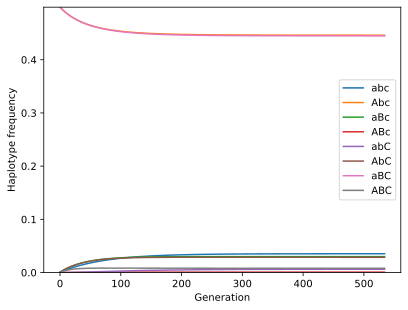

[0.0354 0.4461 0.03   0.0008 0.0062 0.0287 0.4448 0.0081]


In [26]:
# Test the function and plot the result
max_gen = 25000

output = simulate_pop_3(haplo_freq, max_gen, selection_mat_3, mig_vec, rec)

# Show the last few lines of the data table
#print(output[-5:])


# Plot the output
x_range = np.arange(len(output))
haplotypes = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"]

for i in range(len(haplotypes)):
    plt.plot(x_range, output[:, i], label=haplotypes[i])
plt.ylim(0, np.max(output))
plt.xlabel("Generation")
plt.ylabel("Haplotype frequency")
plt.legend()
plt.show()
print(output[-1])

### Functions for plotting

In [27]:
def plot_rec_freqs(haplo_freq, max_gen, selection_mat, mig, rab=0.00001):
    freqs = []
    for i in np.linspace(-4,0.5,20):
        output = simulate_pop_3(haplo_freq, max_gen, selection_mat, mig, [rab, 0.5*10**(i)])
        freqs.append([0.5*10**(i), get_alleles(output[-1])])
        
    plt.plot([i[0] for i in freqs], [i[1] for i in freqs], '--s', label=["A","B","C"], alpha=0.5)
    plt.ylim(0, 1)
    plt.colormaps
    plt.xscale('log')
    plt.xlabel("r_bc")
    plt.ylabel("Allele frequency")
    plt.legend()
    plt.show()
    return(freqs[-1][1])
    

In [28]:
def plot_dyn_haplo(haplo_freq, max_gen, selection_mat, mig, r, title=""):
                          # abc,  Abc, aBc, ABc, abC,  AbC,  aBC,  ABC 
    output = simulate_pop_3(haplo_freq, max_gen, selection_mat, mig, r)
    
    # Show the last few lines of the data table
    #print(output[-5:])
    
    
    # Plot the output
    x_range = np.arange(len(output))
    haplotypes = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"]
    
    for i in range(len(haplotypes)):
        plt.plot(x_range, output[:, i], label=haplotypes[i])
        
    plt.ylim(0, np.max(output)+0.05)
    plt.xlabel("Generation")
    plt.ylabel("Haplotype frequency")
    plt.title(title)
    plt.legend()
    plt.show()
    return(output[-1])

In [29]:
def plot_dyn_freqs(haplo_freq, max_gen, selection_mat, mig, r, title=""):
                          # abc,  Abc, aBc, ABc, abC,  AbC,  aBC,  ABC 
    output = simulate_pop_3(haplo_freq, max_gen, selection_mat, mig, r)
    
    # Show the last few lines of the data table
    #print(output[-5:])
    
    
    # Plot the output
    x_range = np.arange(len(output))
    allele_freq = np.array(list(map(get_alleles, output)))
    alleles = ["A", "B", "C"]
    
    for i in range(len(alleles)):
        plt.plot(x_range, allele_freq[:,i], label=alleles[i])
        
    plt.ylim(0, np.max(allele_freq)+0.05)
    plt.xlabel("Generation")
    plt.ylabel("Allele frequency")
    plt.title(title)
    plt.legend()
    plt.show()
    return(get_alleles(output[-1]))

In [46]:
def plot_heterozygosity_dist(haplo_freq, 
                             max_gen, 
                             selection_mat, 
                             mig, 
                             recombination_list, 
                             palette = {'A':'#5C43AF','B':'#FE842F', 'N':'#194122'},
                             yaxis ='het',
                             allelelist = ['B', 'N'],
                             **kwargs):
    # Plotting different r between A and B
    out = []
    #for rab in [0,0.0001,0.001,0.01,0.1,0.5]:
    for rab in recombination_list:
        freqs = []
        for i in np.linspace(-4,0,20):
            output = simulate_pop_3(haplo_freq, max_gen, selection_mat, mig, [rab, 0.5*10**(i)])
            freqs.append([0.5*10**(i), get_alleles(output[-1])])
        out.append(freqs)
    
    data = []
    alleles = ['A', 'B', 'C']

    for feature_idx, feature in enumerate(out):
        for x_value, y_values in feature:
            for allele, y in zip(alleles, y_values):
                data.append({'r': x_value, 'allele': allele, 'freq': y, 'r_ab': recombination_list[feature_idx]})


    # Create a DataFrame
    df = pd.DataFrame(data)
    df['het'] = 1 - (((df.freq)**2) + ((1-df.freq)**2)) # Calculate heterozygosity
    df['allele'] = df['allele'].replace({'C':'N'})       # Replace 
    df = df[df['allele'].isin(allelelist)]
    
    figfreqs = sns.relplot(data=df, x='r', y=yaxis, hue='allele',
        style='r_ab', kind="line", markers=True,
        palette=palette, alpha=0.8,
        height=6, aspect=1.3)

    legend = figfreqs._legend  
    if legend:
        for text in legend.get_texts():
            if text.get_text() == "allele":
                text.set_text("Allele")  # Change label
            if text.get_text() == "r_ab":
                text.set_text(r"$r_{ab}$")  # Change label
        # Move the legend to the upper right
        legend.set_bbox_to_anchor((0.8, 0.78))  # Position it in the upper right corner
        legend.set_frame_on(True)  


    for ax in figfreqs.axes.flat:
        for line in ax.lines:
            line.set_markersize(8) 

    
    plt.xlabel(r"$r_{bn}$")
    if yaxis=='het':
        plt.ylabel("Heterozygosity")
    elif yaxis=='freq':
        plt.ylabel("Frequency")

    # Get X-axis limits
    ax = figfreqs.ax
    xmin, xmax = ax.get_xlim()

    # Set log scale on x-axis
    ax.set_xscale('log')

    ax.text(0.01, -0.02, "AB", ha='center', va='top', fontsize=10, transform=ax.transAxes)
    ax.text(0.98, -0.02, "→N", ha='center', va='top', fontsize=10, transform=ax.transAxes)
    
    #ax = plt.subplot(111)
    #plt.xscale('log')
    plt.ylim(0, np.max(df[yaxis])+0.05)
    if "title" in kwargs.keys():
        plt.title(kwargs["title"])
    
    plt.show()

    if "filename" in kwargs.keys():
        figfreqs.savefig(kwargs["filename"])
    #plt.savefig('fighet_ppt.svg')

In [50]:
def plot_heterozygosity_dist_neutb(haplo_freq, 
                                   max_gen, 
                                   selection_mat, 
                                   mig, 
                                   recombination_list, 
                                   palette = {'A':'#5C43AF','B':'#FE842F', 'C':'#194122', 'N':'#194122'},
                                   yaxis = 'het',
                                   allelelist = ['B', 'N'],
                                   **kwargs): 
    # Plotting different r between A and B
    
    # Simulate population
    out = []
    for totr in recombination_list:
        for rab in range(0,101,5):
            freqs = []
            #for i in np.linspace(-4,0,20):
            r_ab = totr*rab/100
            r_bc = totr-(totr*rab/100)
            output = simulate_pop_3(haplo_freq, max_gen, selection_mat, [0,0], [r_ab, r_bc])
            freqs.append([r_ab, r_bc, totr, get_alleles(output[-1])])
            out.append(freqs)

    #Extract allele data and create df
    data = []
    alleles = ['A', 'B', 'C']
    for feature_idx, feature in enumerate(out):
        for rab, rbc, totr, y_values in feature:
            for allele, y in zip(alleles, y_values):
                data.append({'rab': rab, 'rbc': rbc, 'pos': rab/totr, 'totr':totr, 'allele': allele, 'freq': y})

    df = pd.DataFrame(data)
    df['het'] = 1 - (((df.freq)**2) + ((1-df.freq)**2))
    df['allele'] = df['allele'].replace({'B':'N'})
    df['allele'] = df['allele'].replace({'A':'B'})
    
    df = df.rename(columns={'totr': 'r_ab'})
    df = df[df['allele'].isin(allelelist)]

    #Plot
    figfreqs = sns.relplot(data=df[df['allele']!='C'], x='pos', y=yaxis, hue='allele',
                           style='r_ab', kind="line", markers=True,
                           palette=palette, alpha=0.8,
                           height=6, aspect=1.3)



    legend = figfreqs._legend  
    if legend:
        for text in legend.get_texts():
            if text.get_text() == "allele":
                text.set_text("Allele")  # Change label
            if text.get_text() == "r_ab":
                text.set_text(r"$r_{ab}$")  # Change label
        # Move the legend to the upper right
        legend.set_bbox_to_anchor((0.8, 0.8))  # Position it in the upper right corner
        legend.set_frame_on(True)  


    for ax in figfreqs.axes.flat:
        for line in ax.lines:
            line.set_markersize(8) 


    plt.xlabel("Relative position of N")
    if yaxis=='het':
        plt.ylabel("Heterozygosity")
    elif yaxis=='freq':
        plt.ylabel("Frequency")

    # Get X-axis limits
    xmin, xmax = ax.get_xlim()

    # Add text "A" at the beginning and "B" at the end of the X-axis
    ax.text(xmin-0.02, -0.02, "A", ha='center', va='top', fontsize=10, transform=ax.transData)
    ax.text(xmax+0.02, -0.02, "B", ha='center', va='top', fontsize=10, transform=ax.transData)

    #ax = plt.subplot(111)
    plt.ylim(0, np.max(df[yaxis])+0.05)
    if "title" in kwargs.keys():
        plt.title(kwargs["title"])
    
    plt.show()

    if "filename" in kwargs.keys():
        figfreqs.savefig(kwargs["filename"])

## Generating some plots

### General dynamics

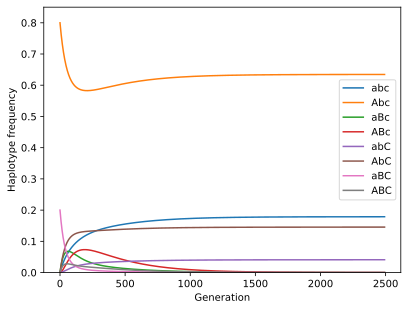

array([1.7873e-01, 6.3453e-01, 3.4342e-05, 9.8698e-05, 4.1003e-02,
       1.4557e-01, 7.8784e-06, 2.2642e-05])

In [53]:
                      # abc,  Abc, aBc, ABc, abC,  AbC,  aBC,  ABC 
haplo_freq = np.array([0.00, 0.8, 0.0, 0.0, 0.00, 0.00, 0.2, 0.00])
overdom_vec = [0,0]
epi_vec = [0.002, 0.004, 0.004, 0.008]

plot_dyn_haplo(haplo_freq, max_gen, get_selection_mat(overdom_vec, epi_vec), [0,0], [0.01,0.02])

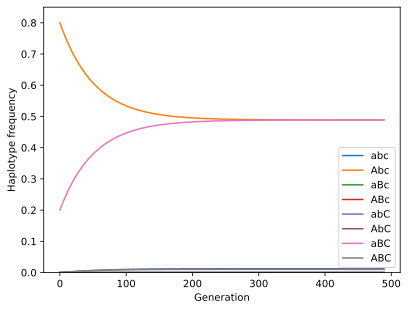

array([1.2298e-02, 4.8876e-01, 1.1711e-05, 4.6868e-07, 6.1369e-07,
       1.1664e-05, 4.8871e-01, 1.0214e-02])

In [54]:
# Example with migration
plot_dyn_haplo(haplo_freq, max_gen, get_selection_mat(overdom_vec, epi_vec), [0.01,0.01], [0.001, 0.000001])


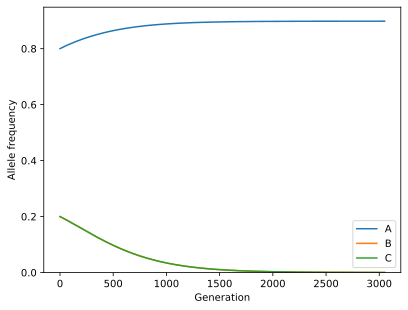

[0.8981284658953707, 0.00019110956003281647, 0.00030901285089116634]

In [55]:
# Plotting dynamics
plot_dyn_freqs(haplo_freq, max_gen, get_selection_mat(overdom_vec, epi_vec), [0,0], [0.001, 0.000001])

###  Plotting different r between A and B

In [56]:
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]
max_gen = 50000
overdom = [0.03,0.03]
epi_vec = [0.03,0.06,0.06,0.12]
mig_vec = [0,0]
rec_vec = [0, 0.0001, 0.001, 0.01, 0.1, 0.5]

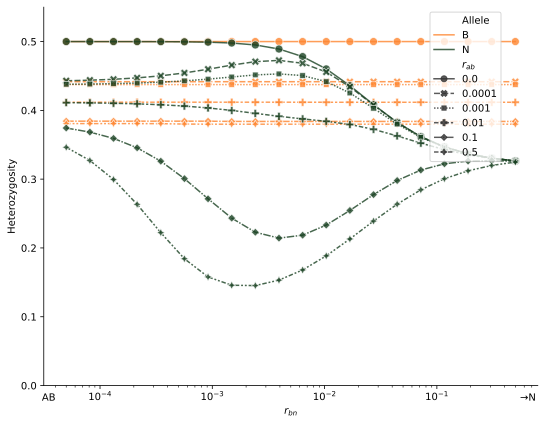

In [98]:
# Using the function, should be equivalent
plot_heterozygosity_dist(haplo_freq, 
                         max_gen, 
                         get_selection_mat(overdom, epi_vec), 
                         mig_vec,
                         rec_vec)


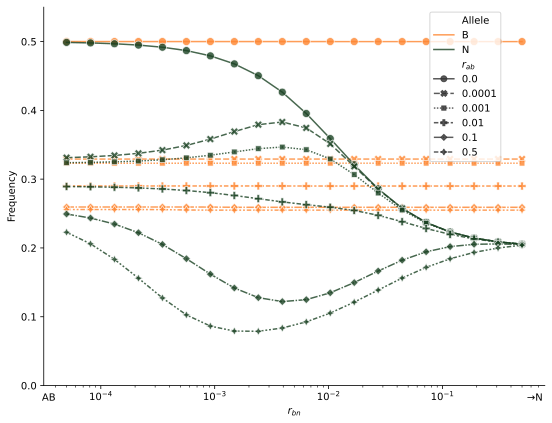

In [99]:
plot_heterozygosity_dist(haplo_freq, 
                         max_gen, 
                         get_selection_mat(overdom, epi_vec), 
                         mig_vec,
                         rec_vec,
                         yaxis='freq')

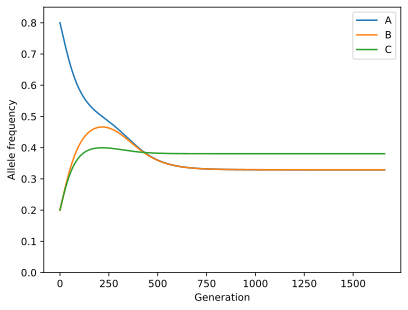

[0.3292062340099323, 0.3292062215539511, 0.38064514894799084]

In [100]:
# For an intermediate value
plot_dyn_freqs(haplo_freq, max_gen, get_selection_mat(overdom, epi_vec), mig_vec, [0.0001,0.005])

### With 2a=g (FIG ->)

In [37]:
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]
overdom = [0.03,0.03]
epi_vec = [0.03,0.06,0.06,0.12]
rab = [0,0.0001,0.1]

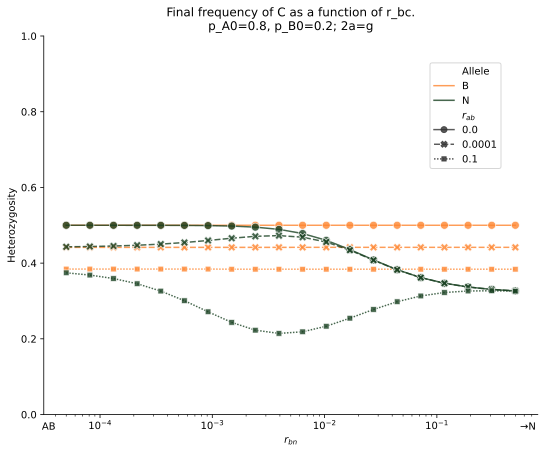

Final frequency of C as a function of r_bc.
p_A0=0.8, p_B0=0.2; 2a=g


In [38]:
plot_heterozygosity_dist(haplo_freq, 
                         max_gen, 
                         get_selection_mat(overdom, epi_vec), 
                         mig_vec,
                         [0,0.0001,0.1],
                         title = 'Final frequency of C as a function of r_bc.\np_A0=0.8, p_B0=0.2; 2a=g') 

#### Individual trajectories

In [38]:
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]

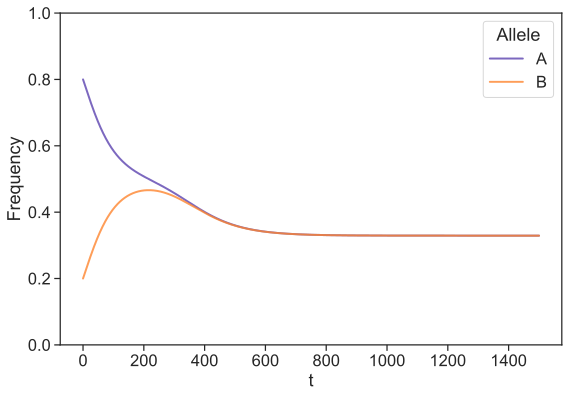

In [39]:
# y = 2a
sns.set(font_scale=1.5)
sns.set_style("ticks")
output = simulate_pop_3(haplo_freq, 1500, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12]), [0,0], [0.0001,0.003924])
allele_freq = np.array(list(map(get_alleles, output)))
dfalleles = pd.DataFrame(allele_freq,columns=['A','B','C'])
dfalleles['t'] = dfalleles.index
dfalleles = dfalleles.melt(id_vars="t", var_name='Allele', value_name='Frequency')

plt.figure(figsize=(6*1.5, 6))
sns.lineplot(data = dfalleles[dfalleles.Allele!='C'], x='t', y='Frequency', hue='Allele', palette=palette, alpha=0.8, linewidth=2)
plt.ylim(0,1)
#plt.show()
plt.savefig('figfreqs_2loci_2a.svg')

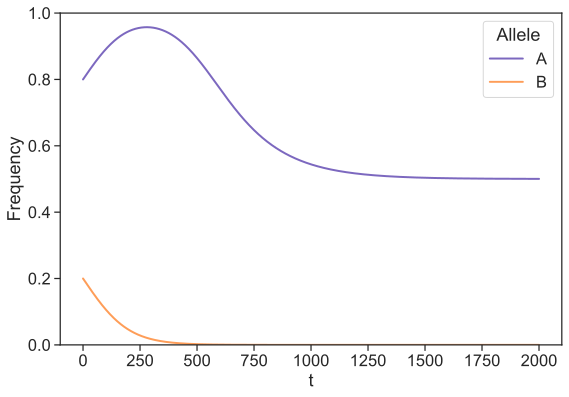

In [40]:
output = simulate_pop_3(haplo_freq, 2000, get_selection_mat([0.01,0.01], [0.03,0.06,0.06,0.12]), [0,0], [0.0001,0.003924])
allele_freq = np.array(list(map(get_alleles, output)))
dfalleles = pd.DataFrame(allele_freq,columns=['A','B','C'])
dfalleles['t'] = dfalleles.index
dfalleles = dfalleles.melt(id_vars="t", var_name='Allele', value_name='Frequency')

plt.figure(figsize=(6*1.5, 6))
sns.lineplot(data = dfalleles[dfalleles.Allele!='C'], x='t', y='Frequency', hue='Allele', palette=palette, alpha=0.8, linewidth=2)
plt.ylim(0,1)
#plt.show()
plt.savefig('figfreqs_2loci_6a.svg')


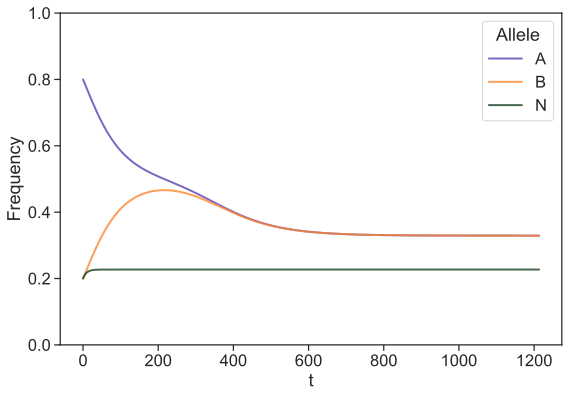

In [41]:
# y = 2a
output = simulate_pop_3(haplo_freq, 1500, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12]), [0,0], [0.0001,0.1])
allele_freq = np.array(list(map(get_alleles, output)))
dfalleles = pd.DataFrame(allele_freq,columns=['A','B','C'])
dfalleles['t'] = dfalleles.index
dfalleles = dfalleles.melt(id_vars="t", var_name='Allele', value_name='Frequency')
dfalleles.Allele = dfalleles.Allele.replace('C','N')

plt.figure(figsize=(6*1.5, 6))
sns.lineplot(data = dfalleles, x='t', y='Frequency', hue='Allele', palette=palette, alpha=0.8, linewidth=2)
plt.ylim(0,1)
#plt.show()
plt.savefig('figfreqs_3loci_2a_rbc1e-1.svg')

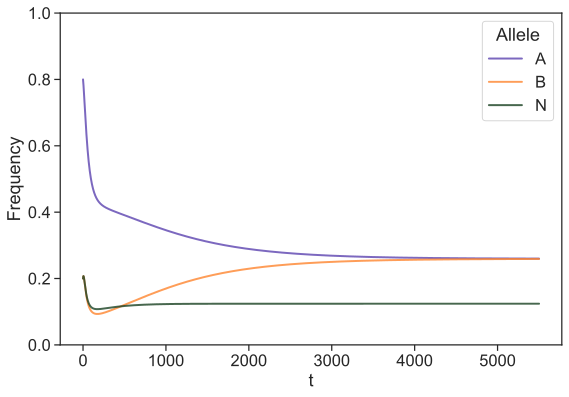

In [42]:
# y = 2a
output = simulate_pop_3(haplo_freq, 5500, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12]), [0,0], [0.1,0.003])
allele_freq = np.array(list(map(get_alleles, output)))
dfalleles = pd.DataFrame(allele_freq,columns=['A','B','C'])
dfalleles['t'] = dfalleles.index
dfalleles = dfalleles.melt(id_vars="t", var_name='Allele', value_name='Frequency')
dfalleles.Allele = dfalleles.Allele.replace('C','N')

plt.figure(figsize=(6*1.5, 6))
sns.lineplot(data = dfalleles, x='t', y='Frequency', hue='Allele', palette=palette, alpha=0.8, linewidth=2)
plt.ylim(0,1)
#plt.show()
plt.savefig('figfreqs_3loci_2a_rab0.1_rbc1e-2.5.svg')

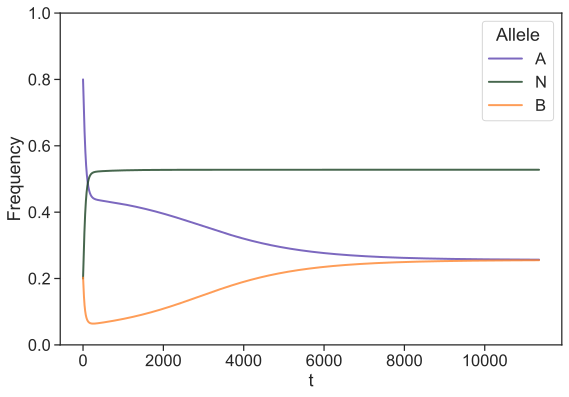

In [43]:
# y = 2a
output = simulate_pop_3(haplo_freq, 15000, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12], neutb=True), [0,0], [0.002,0.430])
allele_freq = np.array(list(map(get_alleles, output)))
dfalleles = pd.DataFrame(allele_freq,columns=['A','B','C'])
dfalleles['t'] = dfalleles.index
dfalleles = dfalleles.melt(id_vars="t", var_name='Allele', value_name='Frequency')

dfalleles.Allele = dfalleles.Allele.replace('B','N')
dfalleles.Allele = dfalleles.Allele.replace('C','B')

plt.figure(figsize=(6*1.5, 6))
sns.lineplot(data = dfalleles, x='t', y='Frequency', hue='Allele', palette=palette, alpha=0.8, linewidth=2)
plt.ylim(0,1)

#plt.show()
plt.savefig('figfreqs_3loci_2a_neutb_rab0.002_rab2e-3.svg')

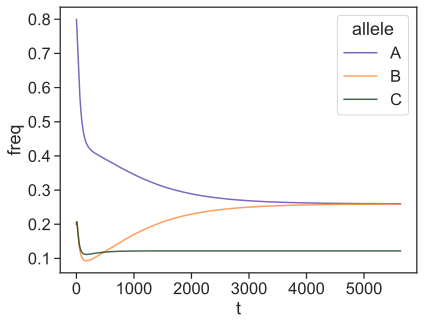

In [44]:
output = simulate_pop_3(haplo_freq, 6000, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12]), [0,0], [0.1,0.003924])
allele_freq = np.array(list(map(get_alleles, output)))
dfalleles = pd.DataFrame(allele_freq,columns=['A','B','C'])
dfalleles['t'] = dfalleles.index
dfalleles = dfalleles.melt(id_vars="t", var_name='allele', value_name='freq')
sns.lineplot(data = dfalleles, x='t', y='freq', hue='allele', palette=palette, alpha=0.8)
#plt.show()
plt.savefig('figfreqsB.svg')

### Recessive DMIs

In [40]:
haplo_freq = [0. , 0.8, 0. , 0. , 0. , 0. , 0.2, 0.]
overdom = [0.03,0.03]
epi_vec = [0,0.12,0.12,0.24]
rab = [0,0.0001,0.1]

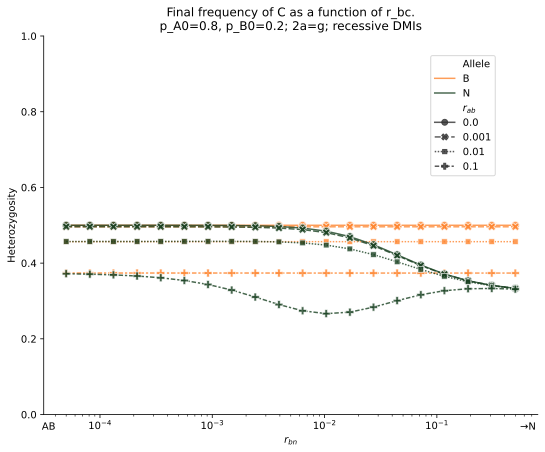

Final frequency of C as a function of r_bc.
p_A0=0.8, p_B0=0.2; 2a=g; recessive DMIs


In [42]:
plot_heterozygosity_dist(haplo_freq, 
                         max_gen, 
                         get_selection_mat(overdom, epi_vec), 
                         mig_vec,
                         [0, 0.001, 0.01, 0.1],
                         title = 'Final frequency of C as a function of r_bc.\np_A0=0.8, p_B0=0.2; 2a=g; recessive DMIs') 

>**Interestingly, there is _never_ an increase in neutral heterozygosity**

## Changing initial frequencies

### pA, pB = 0.5

In [43]:
haplo_freq = [0. , 0.5, 0. , 0. , 0. , 0. , 0.5, 0.]
overdom = [0.03,0.03]
epi_vec = [0.03,0.06,0.06,0.12]
rab = [0,0.0001,0.001,0.01,0.1,0.5]

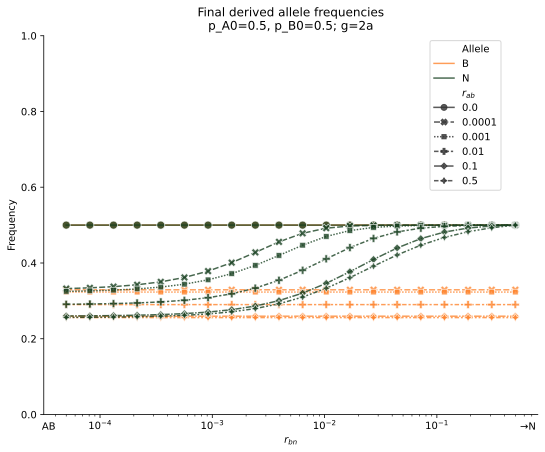

Final derived allele frequencies
p_A0=0.5, p_B0=0.5; g=2a


In [45]:
plot_heterozygosity_dist(haplo_freq, 
                         max_gen, 
                         get_selection_mat(overdom, epi_vec), 
                         mig_vec,
                         [0,0.0001,0.001,0.01,0.1,0.5],
                         yaxis = 'freq',
                         title = 'Final derived allele frequencies\np_A0=0.5, p_B0=0.5; g=2a') 

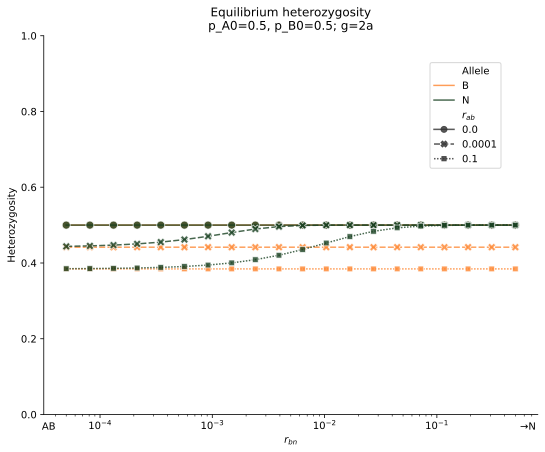

Equilibrium heterozygosity
p_A0=0.5, p_B0=0.5; g=2a


In [47]:
plot_heterozygosity_dist(haplo_freq, 
                         max_gen, 
                         get_selection_mat(overdom, epi_vec), 
                         mig_vec,
                         [0,0.0001,0.1],
                         title = 'Equilibrium heterozygosity\np_A0=0.5, p_B0=0.5; g=2a') 

### Rare C linked to B

In [49]:
#             abc, Abc, aBc,  ABc, abC, AbC, aBC,  ABC,
haplo_freq = [0. , 0.5, 0.49, 0. , 0. , 0. , 0.01, 0.]
overdom = [0.03,0.03]
epi_vec = [0.03,0.06,0.06,0.12]
rab = [0,0.0001,0.001,0.01,0.1,0.5]

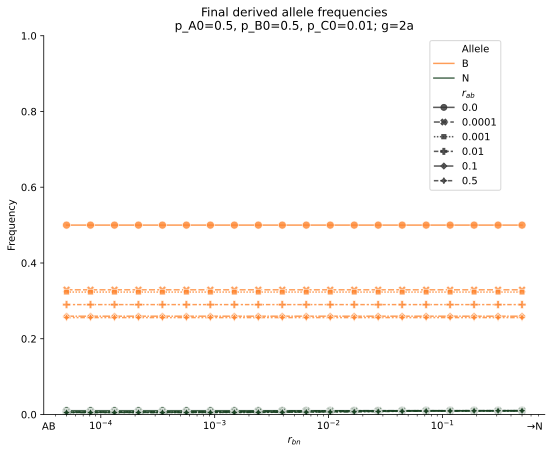

Final derived allele frequencies
p_A0=0.5, p_B0=0.5, p_C0=0.01; g=2a


In [50]:
plot_heterozygosity_dist(haplo_freq, 
                         max_gen, 
                         get_selection_mat(overdom, epi_vec), 
                         mig_vec,
                         rab,
                         yaxis = 'freq',
                         title = 'Final derived allele frequencies\np_A0=0.5, p_B0=0.5, p_C0=0.01; g=2a') 

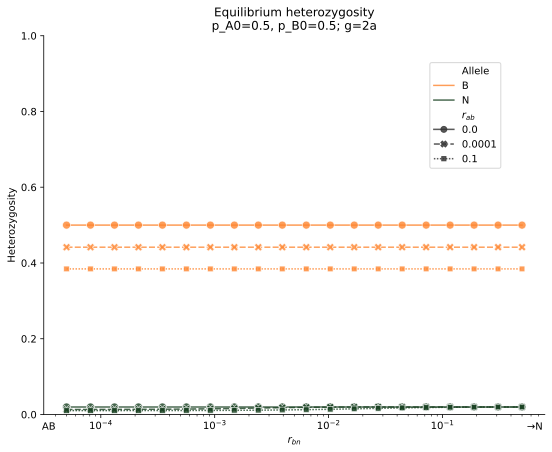

Equilibrium heterozygosity
p_A0=0.5, p_B0=0.5; g=2a


In [51]:
plot_heterozygosity_dist(haplo_freq, 
                         max_gen, 
                         get_selection_mat(overdom, epi_vec), 
                         mig_vec,
                         [0,0.0001,0.1],
                         title = 'Equilibrium heterozygosity\np_A0=0.5, p_B0=0.5; g=2a') 

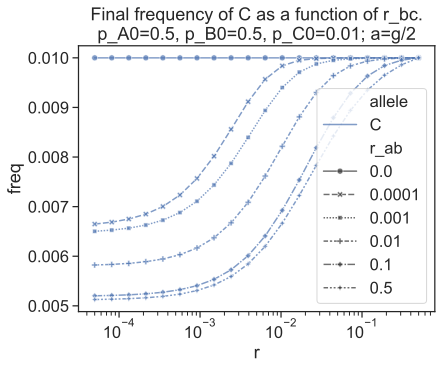

In [52]:
data = []
alleles = ['A', 'B', 'C']
rab = [0,0.0001,0.001,0.01,0.1,0.5]

for feature_idx, feature in enumerate(out):
    for x_value, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'r': x_value, 'allele': allele, 'freq': y, 'r_ab': rab[feature_idx]})

# Create a DataFrame
df = pd.DataFrame(data)
df = df[df['allele']=='C']

# Plot using Seaborn
sns.lineplot(data=df, x='r', y='freq', hue='allele', style='r_ab', markers=True, alpha=0.7)
plt.xscale('log')
plt.title("Final frequency of C as a function of r_bc.\np_A0=0.5, p_B0=0.5, p_C0=0.01; a=g/2")
plt.show()

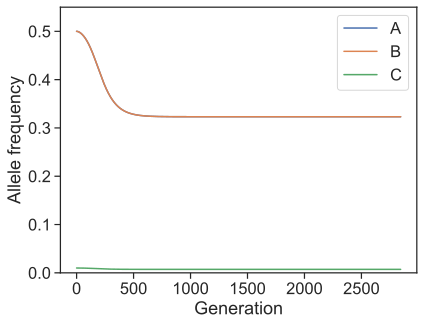

[0.3231648015245138, 0.32316480152451377, 0.007160558002428691]

In [53]:
plot_dyn_freqs(haplo_freq, 50000, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12]), [0,0], [0.001,0.001])

In [54]:
# abc, Abc, aBc, ABc, abC, AbC, aBC, ABC,
haplo_freq = [0,0.5,0.49,0,0,0,0.01,0]

In [55]:
# Plotting different r between A and B
out = []
for rab in [0,0.0001,0.001,0.01,0.1,0.5]:
    freqs = []
    for i in np.linspace(-4,0,20):
        output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12]), [0,0], [rab, 0.5*10**(i)])
        freqs.append([0.5*10**(i), get_alleles(output[-1])])
    out.append(freqs)


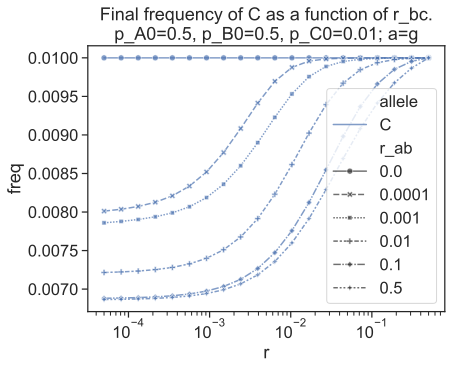

In [56]:
data = []
alleles = ['A', 'B', 'C']
rab = [0,0.0001,0.001,0.01,0.1,0.5]

for feature_idx, feature in enumerate(out):
    for x_value, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'r': x_value, 'allele': allele, 'freq': y, 'r_ab': rab[feature_idx]})

# Create a DataFrame
df = pd.DataFrame(data)
df = df[df['allele']=='C']

# Plot using Seaborn
sns.lineplot(data=df, x='r', y='freq', hue='allele', style='r_ab', markers=True, alpha=0.7)
plt.xscale('log')
plt.title("Final frequency of C as a function of r_bc.\np_A0=0.5, p_B0=0.5, p_C0=0.01; a=g")
plt.show()

C increases frequency with increasing r

### Less rare C (C_0=0.05) and different initial condition for A (0.8) and B (0.2)

In [57]:
# abc, Abc, aBc, ABc, abC, AbC, aBC, ABC,
haplo_freq = [0,0.8,0.15,0,0,0,0.05,0]

In [58]:
# Plotting different r between A and B
out = []
for rab in [0,0.0001,0.001,0.01,0.1,0.5]:
    freqs = []
    for i in np.linspace(-4,0,20):
        output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12]), [0,0], [rab, 0.5*10**(i)])
        freqs.append([0.5*10**(i), get_alleles(output[-1])])
    out.append(freqs)


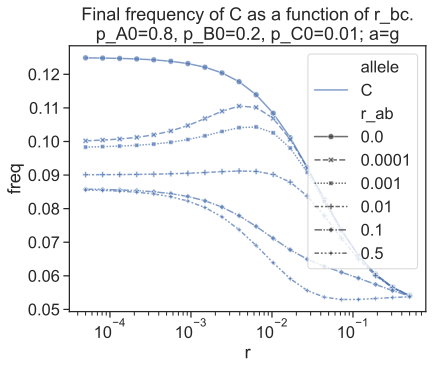

In [59]:
data = []
alleles = ['A', 'B', 'C']
rab = [0,0.0001,0.001,0.01,0.1,0.5]

for feature_idx, feature in enumerate(out):
    for x_value, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'r': x_value, 'allele': allele, 'freq': y, 'r_ab': rab[feature_idx]})

# Create a DataFrame
df = pd.DataFrame(data)
df = df[df['allele']=='C']

# Plot using Seaborn
sns.lineplot(data=df, x='r', y='freq', hue='allele', style='r_ab', markers=True, alpha=0.7)
plt.xscale('log')
plt.title("Final frequency of C as a function of r_bc.\np_A0=0.8, p_B0=0.2, p_C0=0.01; a=g")
plt.show()

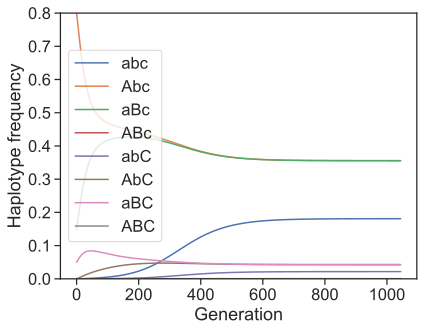

array([1.8106e-01, 3.5563e-01, 3.5562e-01, 4.7327e-04, 2.1744e-02,
       4.2708e-02, 4.2710e-02, 5.6839e-05])

In [60]:
plot_dyn_haplo(haplo_freq, 50000, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12]), [0,0], [0.0001,0.01])

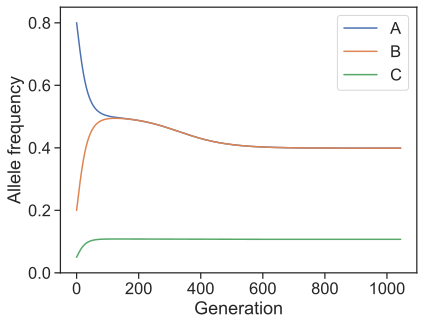

[0.39886483402537115, 0.3988648340253711, 0.1072188773087505]

In [61]:
plot_dyn_freqs(haplo_freq, 50000, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12]), [0,0], [0.0001,0.01])

### With P_B0 > P_A0

In [ ]:
# abc, Abc, aBc, ABc, abC, AbC, aBC, ABC,
haplo_freq = [0,0.2,0.75,0,0,0,0.05,0]

In [ ]:
# Plotting different r between A and B
out = []
for rab in [0,0.0001,0.001,0.01,0.1,0.5]:
    freqs = []
    for i in np.linspace(-4,0,20):
        output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12]), [0,0], [rab, 0.5*10**(i)])
        freqs.append([0.5*10**(i), get_alleles(output[-1])])
    out.append(freqs)


In [ ]:
data = []
alleles = ['A', 'B', 'C']
rab = [0,0.0001,0.001,0.01,0.1,0.5]

for feature_idx, feature in enumerate(out):
    for x_value, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'r': x_value, 'allele': allele, 'freq': y, 'r_ab': rab[feature_idx]})

# Create a DataFrame
df = pd.DataFrame(data)
df = df[df['allele']=='C']

# Plot using Seaborn
sns.lineplot(data=df, x='r', y='freq', hue='allele', style='r_ab', markers=True, alpha=0.7)
plt.xscale('log')
plt.title("Final frequency of C as a function of r_bc.\np_A0=0.2, p_B0=0.8, p_C0=0.05; a=g")
plt.show()

In [ ]:
haplo_freq = [0,0.2,0.75,0,0,0,0.05,0]
plot_dyn_haplo(haplo_freq, 50000, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12]), [0,0], [0.0001,0.01])

In [ ]:
plot_dyn_freqs(haplo_freq, 50000, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12]), [0,0], [0.01,0.01], title="Allele dynamics.\np_A0=0.2, p_B0=0.8; P_C0=0.05; a=g")

In [ ]:
#plot_dyn_freqs(haplo_freq, 50000, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12]), [0,0], [0.01,0.01], title="Allele dynamics.\np_A0=0.2, p_B0=0.8; P_C0=0.05; a=g")

## Marginal fitnesses 

In [ ]:
output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12]), [0,0], [0.001,0.001])
    
# Show the last few lines of the data table
#print(output[-5:])

# Plot the output
x_range = np.arange(len(output))
allele_freq = np.array(map(get_alleles, output))

In [ ]:
selection_mat_tst = get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12])

In [ ]:
selection_mat_tst

In [ ]:
geno_mat = np.outer(output[-1], output[-1])
geno_mat

In [ ]:
#np.dot(output[-1],selection_mat_tst)
outwmarg = np.array([np.dot(output[i],selection_mat_tst) for i in range(len(output))])
x_range = np.arange(len(output))
haplotypes = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"]

for i in range(len(haplotypes)):
    plt.plot(x_range, outwmarg[:, i], label=haplotypes[i])
    
#plt.ylim(0, np.max(outwmarg))
plt.xlabel("Generation")
plt.ylabel("Marginal fitness")
plt.legend()
plt.show()


In [ ]:
#marginal fitnesses for one generation:
wmarg = outwmarg[0]
wmarg


In [ ]:
for feature_idx, feature in enumerate(output):
    for x_value, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'r': x_value, 'allele': allele, 'freq': y, 'r_ab': rab[feature_idx]})

# Create a DataFrame
df = pd.DataFrame(data)
df = df[df['allele']!='A']

In [ ]:
x_range = np.arange(len(output))
haplotypes = ["abc", "Abc", "aBc", "ABc", "abC", "AbC", "aBC", "ABC"]

df_haplo = pd.DataFrame(output, columns=haplotypes)
df_haplo['t'] = range(len(output))
df_haplo = df_haplo[['t'] + haplotypes]

longdf = df_haplo.melt(id_vars=['t'], var_name='haplotype', value_name='freq')

In [ ]:
# Pivot to wide format
wide_df = longdf.pivot(index='t', columns='haplotype', values='freq')

# Create a stacked area plot
fig, ax = plt.subplots(figsize=(10, 6))
haplos = wide_df.columns
ax.stackplot(wide_df.index, wide_df.T, labels=haplos, alpha=0.8, colors=sns.color_palette("tab10", len(haplos)))

# Customize the plot
ax.set_title("Müller Plot of Haplotypes", fontsize=16)
ax.set_xlabel("t", fontsize=14)
ax.set_ylabel("freq", fontsize=14)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## Neutral B, with different r_AB and r_BC

In [80]:
# abc, Abc, aBc, ABc, abC, AbC, aBC, ABC,
haplo_freq = [0,0.8,0,0,0,0,0.2,0]
# Plotting different r between A and B
out = []
for rab in range(0,433):
    freqs = []
    #for i in np.linspace(-4,0,20):
    r_ab = rab/1000
    r_bc = 0.432-(rab/1000)
    output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12], neutb=True), [0,0], [r_ab, r_bc])
    freqs.append([r_ab, r_bc, get_alleles(output[-1])])
    out.append(freqs)

data = []
alleles = ['A', 'B', 'C']



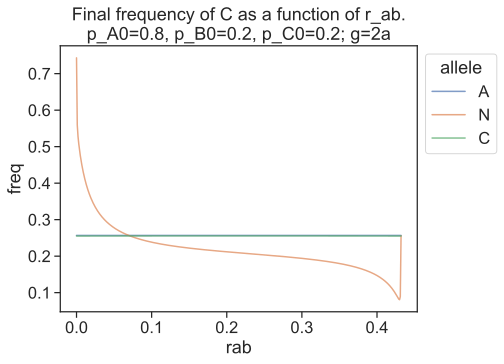

In [81]:
for feature_idx, feature in enumerate(out):
    for rab, rbc, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'rab': rab, 'rbc': rbc, 'allele': allele, 'freq': y})

# Create a DataFrame
df = pd.DataFrame(data)
df['het'] = 1 - (((df.freq)**2) + ((1-df.freq)**2))
df.allele = df.allele.replace('B','N')
# PPT fig
ax = sns.lineplot(data=df, x='rab', y='freq', hue='allele', markers='allele',  alpha=0.7)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title("Final frequency of C as a function of r_ab.\np_A0=0.8, p_B0=0.2, p_C0=0.2; g=2a")
plt.show()

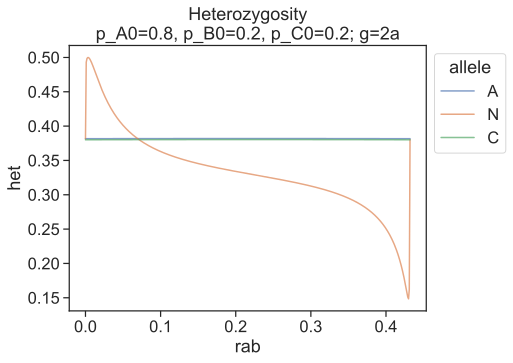

In [82]:
ax = sns.lineplot(data=df, x='rab', y='het', hue='allele', markers='allele',  alpha=0.7)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title("Heterozygosity\np_A0=0.8, p_B0=0.2, p_C0=0.2; g=2a")
plt.show()

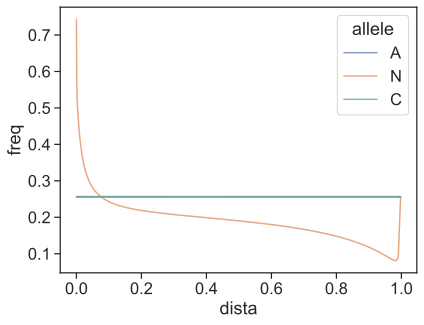

In [83]:
df['dista'] = -0.5* np.log(1-2*df.rab)
# Plot using Seaborn
sns.lineplot(data=df, x='dista', y='freq', hue='allele',  alpha=0.7)
#plt.title("Final frequency of C as a function of r_bc.\np_A0=0.5, p_B0=0.5, p_C0=0.01; a=g/2")
plt.show()

In [84]:
            #abc, Abc, aBc, ABc, abC, AbC, aBC, ABC,
haplo_freq = [0,  0.4,   0,   0,   0,  0,  0.6,  0]

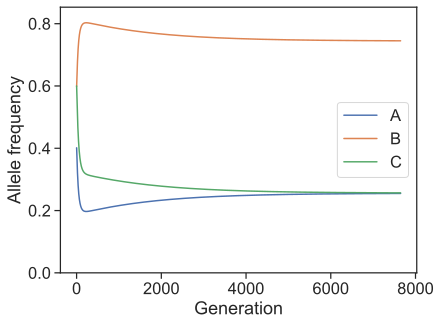

[0.2549640251523012, 0.7450359748476986, 0.2566839473831074]

In [85]:
plot_dyn_freqs(haplo_freq, 50000, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12], neutb=True), [0,0], [0,0.5])


### Rare B

In [ ]:
            #abc, Abc, aBc, ABc, abC, AbC, aBC, ABC,
haplo_freq = [0,  0.4,   0,   0,  0.58,  0,  0.02,  0]

In [ ]:
# Plotting different r between A and B
out = []
for rab in range(0,500):
    freqs = []
    #for i in np.linspace(-4,0,20):
    r_ab = rab/1000
    r_bc = 0.5-(rab/1000)
    output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12], neutb=True), [0,0], [r_ab, r_bc])
    freqs.append([r_ab, r_bc, get_alleles(output[-1])])
    out.append(freqs)

data = []
alleles = ['A', 'B', 'C']

In [ ]:
for feature_idx, feature in enumerate(out):
    for rab, rbc, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'rab': rab, 'rbc': rbc, 'allele': allele, 'freq': y})

# Create a DataFrame
df = pd.DataFrame(data)

# Plot using Seaborn
sns.lineplot(data=df, x='rab', y='freq', hue='allele',  alpha=0.7)
plt.title("Final frequency of C as a function of r_ab.\np_A0=0.4, p_B0=0.02, p_C0=0.6; a=g/2")
plt.show()

In [ ]:
df = pd.DataFrame(data)
df2 = df[df['allele']=='B']
# Plot using Seaborn
sns.lineplot(data=df2, x='rab', y='freq', hue='allele',  alpha=0.7)
plt.title("Final frequency of C as a function of r_ab.\np_A0=0.4, p_B0=0.02, p_C0=0.6; a=g/2")
plt.show()

In [ ]:
plot_dyn_freqs(haplo_freq, 50000, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12], neutb=True), [0,0], [0,0.5])

## Different distance between A and B with equal distance between points

In [86]:
            #abc, Abc, aBc, ABc, abC, AbC, aBC, ABC,
haplo_freq = [0,  0.8,   0,   0,  0,  0,  0.2,  0]

In [87]:
# Plotting different r between A and B
out = []
allr = [0.001,0.01,0.1,0.432,0.4908]
for totr in allr:
    step = 1/totr
    for rab in range(0,101,5):
        freqs = []
        #for i in np.linspace(-4,0,20):
        r_ab = totr*rab/100
        r_bc = totr-(totr*rab/100)
        output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12], neutb=True), [0,0], [r_ab, r_bc])
        freqs.append([r_ab, r_bc, totr, get_alleles(output[-1])])
        out.append(freqs)



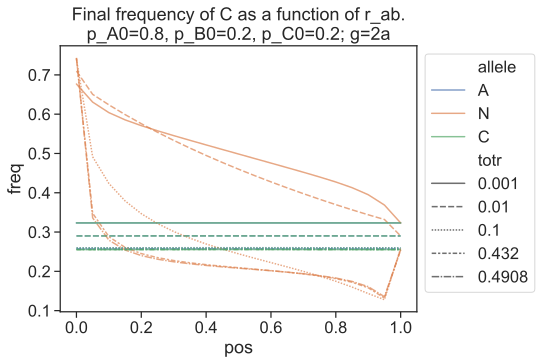

In [88]:
data = []
alleles = ['A', 'B', 'C']
for feature_idx, feature in enumerate(out):
    for rab, rbc, totr, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'rab': rab, 'rbc': rbc, 'pos': rab/totr, 'totr':totr, 'allele': allele, 'freq': y})

# Create a DataFrame
df = pd.DataFrame(data)
df['het'] = 1 - (((df.freq)**2) + ((1-df.freq)**2))
df.allele = df.allele.replace('B','N')
# PPT fig
ax = sns.lineplot(data=df, x='pos', y='freq', hue='allele', style='totr',  alpha=0.7)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title("Final frequency of C as a function of r_ab.\np_A0=0.8, p_B0=0.2, p_C0=0.2; g=2a")
plt.show()

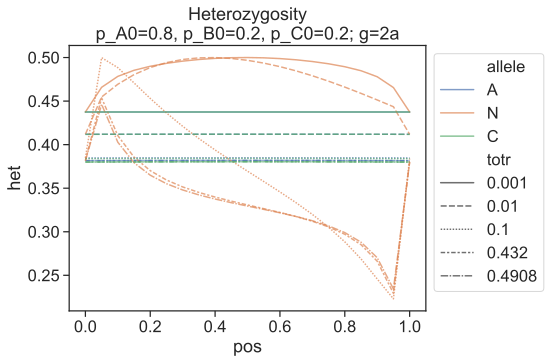

In [89]:
ax = sns.lineplot(data=df, x='pos', y='het', hue='allele', style='totr',  alpha=0.7)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title("Heterozygosity\np_A0=0.8, p_B0=0.2, p_C0=0.2; g=2a")
plt.show()

In [90]:
dffiltered = df[df['totr'].isin([0.001,0.432])]

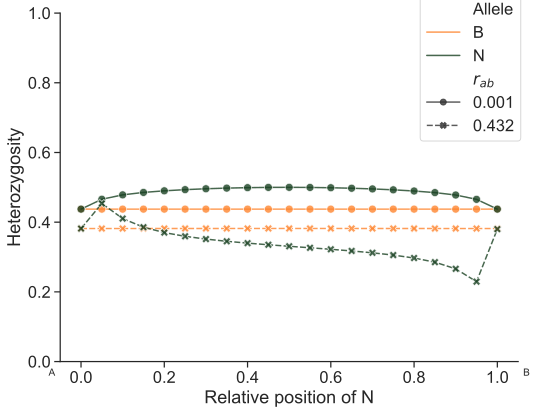

In [93]:
dffiltered2 = dffiltered
dffiltered2['allele'] = dffiltered2['allele'].replace({'A':'B'})
dffiltered2 = dffiltered2.rename(columns={'totr': 'r_ab'})

palette = {'A':'#5C43AF','B':'#FE842F', 'C':'#194122', 'N':'#194122'}
figfreqs = sns.relplot(data=dffiltered2[dffiltered2['allele']!='C'], x='pos', y='het', hue='allele',
                       style='r_ab', kind="line", markers=True,
                       palette=palette, alpha=0.8,
                       height=6, aspect=1.3)



legend = figfreqs._legend  
if legend:
    for text in legend.get_texts():
        if text.get_text() == "allele":
            text.set_text("Allele")  # Change label
        if text.get_text() == "r_ab":
            text.set_text(r"$r_{ab}$")  # Change label
    # Move the legend to the upper right
    legend.set_bbox_to_anchor((0.8, 0.8))  # Position it in the upper right corner
    legend.set_frame_on(True)  


for ax in figfreqs.axes.flat:
    for line in ax.lines:
        line.set_markersize(8) 

plt.xlabel("Relative position of N")
plt.ylabel("Heterozygosity")

# Get X-axis limits
xmin, xmax = ax.get_xlim()

# Add text "A" at the beginning and "B" at the end of the X-axis
ax.text(xmin-0.02, -0.02, "A", ha='center', va='top', fontsize=10, transform=ax.transData)
ax.text(xmax+0.02, -0.02, "B", ha='center', va='top', fontsize=10, transform=ax.transData)

#ax = plt.subplot(111)
plt.ylim(0, 1)
#plt.title("Final frequency of C as a function of r_bc.\np_A0=0.8, p_B0=0.2; a=g")
plt.show()

#plt.savefig('fighet_neutb.svg')
#plt.savefig('fighet_neutb_ppt.svg')

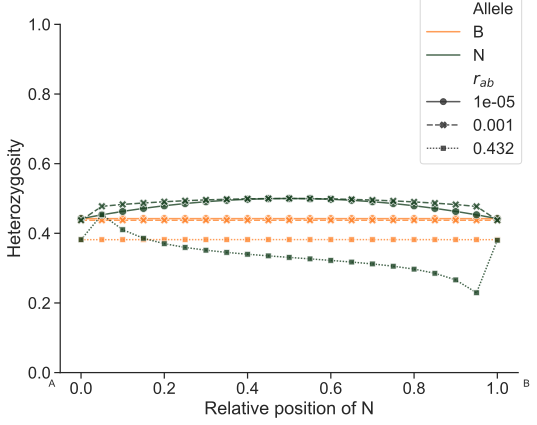

In [144]:
dfuneq_neutb = plot_heterozygosity_dist_neutb([0,  0.8,   0,   0,  0,  0,  0.2,  0],
                              100000,
                              get_selection_mat([0.03,0.03],[0.03,0.06,0.06,0.12], neutb=True),
                              [0,0],
                              [0.00001,0.001,0.432])

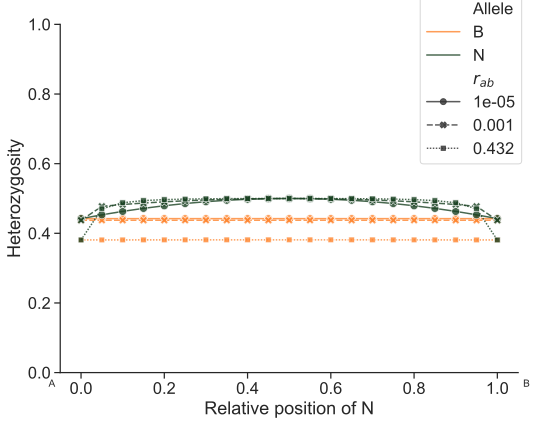

In [145]:
plot_heterozygosity_dist_neutb([0,  0.5,   0,   0,  0,  0,  0.5,  0],
                              100000,
                              get_selection_mat([0.03,0.03],[0.03,0.06,0.06,0.12]),
                              [0,0],
                              [0.00001,0.001,0.432])

## Distance plots
#### Neutral locus at different positions

Assuming a linkage map of 1 M (r = 0.432332)
First, I check the frequency of a neutral locus at the end of the sequence, fixing the distance between the other two loci

In [147]:
# abc, Abc, aBc, ABc, abC, AbC, aBC, ABC,
haplo_freq = [0,0.6,0,0,0,0,0.4,0]
# Plotting different r between A and B
out = []
for rbc in range(0,432):
    freqs = []
    #for i in np.linspace(-4,0,20):
    r_ab = 0.4323
    r_bc = rbc/1000
    output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12]), [0,0], [r_ab, r_bc])
    freqs.append([r_ab, r_bc, get_alleles(output[-1])])
    out.append(freqs)




In [ ]:
data = []
alleles = ['A', 'B', 'C']

for feature_idx, feature in enumerate(out):
    for rab, rbc, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'rab': rab, 'rbc': rbc, 'allele': allele, 'freq': y})

# Create a DataFrame
df_cneut = pd.DataFrame(data)

In [ ]:
df_cneut['dista'] = -0.5* np.log(1-2*df_cneut.rbc)
df_cneut.allele = df_cneut.allele.replace('C','N')
# Plot using Seaborn
sns.lineplot(data=df_cneut, x='dista', y='freq', hue='allele',  alpha=0.7)
plt.title("Final frequency of neutral as a function of r_ab.\np_A0=0.6, p_B0=0.4, p_C0=0.4; a=g/2")
plt.show()

Ah! If I want to be consistent I have to put a distance of 1 between A and B

For neutral A I just need to change initial conditions?
i.e., AB = 0.4 and C = 0.6 (?)

In [ ]:
            # abc, Abc, aBc, *ABc, *abC, AbC, aBC, ABC,
haplo_freq = [0,0,0,0.4,0.6,0,0,0]
# Plotting different r between A and B
out = []
for rbc in range(0,432):
    freqs = []
    #for i in np.linspace(-4,0,20):
    r_ab = 0.4323
    r_bc = rbc/1000
    output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12]), [0,0], [r_ab, r_bc])
    freqs.append([r_ab, r_bc, get_alleles(output[-1])])
    out.append(freqs)




In [ ]:
data = []
alleles = ['A', 'B', 'C']

for feature_idx, feature in enumerate(out):
    for rab, rbc, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'rab': rab, 'rbc': rbc, 'allele': allele, 'freq': y})

# Create a DataFrame
df_aneut = pd.DataFrame(data)

In [ ]:
df_aneut['dista'] = -0.5* np.log(1-2*df_aneut.rbc)
df_aneut['dista'] = -1 * (df_aneut.dista - 1)
df_aneut.allele = df_aneut.allele.replace('C','N')
# Plot using Seaborn
sns.lineplot(data=df_aneut, x='dista', y='freq', hue='allele',  alpha=0.7)
plt.title("Final frequency of neutral as a function of r_ab.\np_A0=0.4, p_B0=0.6, p_C0=0.6; a=g/2")
plt.show()

In [ ]:
# In theory, neutral freq at the end should be like freq at the beginning of neutral b (~0.75)

In [ ]:
# haplo_freq = [0,0,0,0.4,0.6,0,0,0]
            # abc, Abc, aBc, *ABc, *abC, AbC, aBC, ABC,
haplo_freq = [0,   0,    0,   0.4, 0.6,   0,   0,   0]
plot_dyn_freqs(haplo_freq, 50000, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12]), [0,0], [0.4323,0.0001])

In [ ]:
# haplo_freq = [0,0,0,0.4,0.6,0,0,0]
            # abc, Abc, aBc, *ABc, *abC, AbC, aBC, ABC,
haplo_freq = [0,   0.5,    0,   0  , 0,   0,  0.5,   0]
plot_dyn_freqs(haplo_freq, 50000, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12], neutb=True), [0,0], [0.01,0.432])

In [ ]:
plot_dyn_haplo(haplo_freq, 1000000, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12], neutb=True), [0,0], [0.01,0.432])

And for the neutral locus in the middle

In [ ]:
# abc, Abc, aBc, ABc, abC, AbC, aBC, ABC,
haplo_freq = [0,0.6,0,0,0,0,0.4,0]
# Plotting different r between A and B
out = []
for rab in range(0,432):
    freqs = []
    #for i in np.linspace(-4,0,20):
    r_ab = rab/1000
    r_bc = 0.4323-(rab/1000)
    output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12], neutb=True), [0,0], [r_ab, r_bc])
    freqs.append([r_ab, r_bc, get_alleles(output[-1])])
    out.append(freqs)




In [ ]:
data = []
alleles = ['A', 'B', 'C']

for feature_idx, feature in enumerate(out):
    for rab, rbc, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'rab': rab, 'rbc': rbc, 'allele': allele, 'freq': y})

# Create a DataFrame
df_bneut = pd.DataFrame(data)

In [ ]:
df_bneut['dista'] = -0.5* np.log(1-2*df.rab)
df_bneut.allele = df_bneut.allele.replace('B','N')

# Plot using Seaborn
sns.lineplot(data=df_bneut, x='dista', y='freq', hue='allele',  alpha=0.7)
plt.title("Final frequency of C as a function of r_ab.\np_A0=0.6, p_B0=0.4, p_C0=0.4; a=g/2")
plt.show()

In [ ]:
df_bneut['dista'] = df_bneut['dista']+1.0
df_cneut['dista'] = df_cneut['dista']+2.0

In [ ]:
df_full = pd.concat([df_aneut,df_bneut, df_cneut])

In [ ]:
sns.lineplot(data=df_full, x='dista', y='freq', hue='allele',  alpha=0.7)
plt.title("Final frequency of neutral locus as a function of distance.\np_A0=0.6, p_B0=0.4, p_C0=0.4; a=g/2")
plt.show()

In [ ]:
df_full2 = df_full

In [ ]:
df_full2.loc[(df_full2.allele == 'C') & (df_full2.dista>=2), 'allele'] = 'N'
df_full2.loc[(df_full2.allele == 'C') & (df_full2.dista<2), 'allele'] = 'B'

In [ ]:
df_full2['het'] = 1 - (((df_full2.freq)**2) + ((1-df_full2.freq)**2))

In [ ]:
sns.lineplot(data=df_full2, x='dista', y='het', hue='allele',  alpha=0.7)
plt.title("Final frequency of neutral locus as a function of distance.\np_A0=0.6, p_B0=0.4, p_C0=0.4; a=g/2")
plt.show()

In [ ]:
### Maybe I will start with 0.5 and 0.5 for simplicity

In [ ]:
# Neutral C
# abc, Abc, aBc, ABc, abC, AbC, aBC, ABC,
haplo_freq = [0,0.5,0,0,0,0,0.5,0]
# Plotting different r between A and B
out = []
for rbc in range(0,432):
    freqs = []
    #for i in np.linspace(-4,0,20):
    r_ab = 0.4323
    r_bc = rbc/1000
    output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12]), [0,0], [r_ab, r_bc])
    freqs.append([r_ab, r_bc, get_alleles(output[-1])])
    out.append(freqs)




In [ ]:
data = []
alleles = ['A', 'B', 'C']

for feature_idx, feature in enumerate(out):
    for rab, rbc, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'rab': rab, 'rbc': rbc, 'allele': allele, 'freq': y})

# Create a DataFrame
df_cneut = pd.DataFrame(data)

df_cneut['dista'] = -0.5* np.log(1-2*df_cneut.rbc)
df_cneut.allele = df_cneut.allele.replace('C','N')
# Plot using Seaborn
sns.lineplot(data=df_cneut, x='dista', y='freq', hue='allele',  alpha=0.7)
plt.title("Final frequency of neutral as a function of r_ab.\np_A0=0.5, p_B0=0.5, p_C0=0.5; a=g/2")
plt.show()

In [ ]:
# Neutral B
            # abc, Abc, aBc, ABc, abC, AbC, aBC, ABC,
haplo_freq = [0,    0.5, 0,   0,   0,   0,   0.5, 0]
# Plotting different r between A and B
out = []
for rab in range(0,433):
    freqs = []
    #for i in np.linspace(-4,0,20):
    r_ab = rab/1000
    r_bc = 0.432-(rab/1000)
    output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12], neutb=True), [0,0], [r_ab, r_bc])
    freqs.append([r_ab, r_bc, get_alleles(output[-1])])
    out.append(freqs)




In [ ]:
data = []
alleles = ['A', 'B', 'C']

for feature_idx, feature in enumerate(out):
    for rab, rbc, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'rab': rab, 'rbc': rbc, 'allele': allele, 'freq': y})

# Create a DataFrame
df_bneut = pd.DataFrame(data)

df_bneut['dista'] = -0.5* np.log(1-2*df.rab)
df_bneut.allele = df_bneut.allele.replace('B','N')
df_bneut.allele = df_bneut.allele.replace('C','B')
df_bneut['het'] = 1 - (((df_bneut.freq)**2) + ((1-df_bneut.freq)**2))

ax = sns.lineplot(data=df_bneut, x='rab', y='freq', hue='allele',  alpha=0.8)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title("Final derived allele frequencies within a linkage map of 1m\np_A0=0.5, p_B0=0.5, p_C0=0.5; g=2a")
plt.show()

In [ ]:
ax = sns.lineplot(data=df_bneut, x='rab', y='het', hue='allele', markers=True,  alpha=0.8)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.title("Heterozygosity \np_A0=0.5, p_B0=0.5, p_C0=0.5; g=2a")
plt.show()

In [ ]:
# Neutral B
            # abc, Abc, aBc, ABc, abC, AbC, aBC, ABC,
haplo_freq = [0,   0.5,   0,   0,   0,   0,  0.5, 0]
# Plotting different r between A and B
out = []
for rab in range(0,432):
    freqs = []
    #for i in np.linspace(-4,0,20):
    r_ab = rab/1000
    r_bc = 0.4323-(rab/1000)
    output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12], neutb=True), [0,0], [r_ab, r_bc])
    freqs.append([r_ab, r_bc, get_alleles(output[-1])])
    out.append(freqs)




In [ ]:
data = []
alleles = ['A', 'B', 'C']

for feature_idx, feature in enumerate(out):
    for rab, rbc, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'rab': rab, 'rbc': rbc, 'allele': allele, 'freq': y})

# Create a DataFrame
df_bneut = pd.DataFrame(data)

df_bneut['dista'] = -0.5* np.log(1-2*df.rab)
df_bneut.allele = df_bneut.allele.replace('B','N')
df_bneut.allele = df_bneut.allele.replace('C','B')

# Plot using Seaborn
sns.lineplot(data=df_bneut, x='dista', y='freq', hue='allele',  alpha=0.7)
plt.title("Final frequency of C as a function of r_ab.\np_A0=0.5, p_B0=0.5, p_C0=0.5; a=g/2")
plt.show()

In [ ]:
# Neutral B
            # abc, Abc, aBc, ABc, abC, AbC, aBC, ABC,
haplo_freq = [0,   0.5,  0,  0,  0.4,   0, 0.1, 0]
# Plotting different r between A and B
out = []
for rab in range(0,432):
    freqs = []
    #for i in np.linspace(-4,0,20):
    r_ab = rab/1000
    r_bc = 0.4323-(rab/1000)
    output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0.03,0.03], [0.003,0.006,0.006,0.012], neutb=True), [0,0], [r_ab, r_bc])
    freqs.append([r_ab, r_bc, get_alleles(output[-1])])
    out.append(freqs)

data = []
alleles = ['A', 'B', 'C']

for feature_idx, feature in enumerate(out):
    for rab, rbc, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'rab': rab, 'rbc': rbc, 'allele': allele, 'freq': y})

# Create a DataFrame
df_bneut = pd.DataFrame(data)

df_bneut['dista'] = -0.5* np.log(1-2*df.rab)
df_bneut.allele = df_bneut.allele.replace('B','N')
df_bneut.allele = df_bneut.allele.replace('C','B')

# Plot using Seaborn
sns.lineplot(data=df_bneut, x='dista', y='freq', hue='allele',  alpha=0.7)
plt.title("Final frequency of C as a function of r_ab.\np_A0=0.5, p_B0=0.5, p_C0=0.1; a=g/2")
plt.show()


In [ ]:
# Plot using Seaborn
sns.lineplot(data=df_bneut[df_bneut['allele']=='N'], x='dista', y='freq', hue='allele',  alpha=0.7)
plt.title("Final frequency of C as a function of r_ab.\np_A0=0.5, p_B0=0.5, p_C0=0.1; a=g/2")
plt.show()

In [ ]:
df_bneut

### No DMIs, heterosis only

First I will make a function to join all three cases, should make things easier

In [ ]:
# Neutral B
            # abc, Abc, aBc, ABc, abC, AbC, aBC, ABC,
haplo_freq = [0,   0.5,  0,   0,  0,  0,    0.5,  0]
# Plotting different r between A and B
out = []
for rab in range(0,501):
    freqs = []
    #for i in np.linspace(-4,0,20):
    r_ab = rab/1000
    r_bc = 0.5-(rab/1000)
    output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12], neutb=True), [0,0], [r_ab, r_bc])
    freqs.append([r_ab, r_bc, get_alleles(output[-1])])
    out.append(freqs)

data = []
alleles = ['A', 'B', 'C']

for feature_idx, feature in enumerate(out):
    for rab, rbc, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'rab': rab, 'rbc': rbc, 'allele': allele, 'freq': y})




In [ ]:
# Create a DataFrame
df_bneut = pd.DataFrame(data)

df_bneut['dista'] = -0.5* np.log(1-2*df.rab)
df_bneut.allele = df_bneut.allele.replace('B','N')
df_bneut.allele = df_bneut.allele.replace('C','B')
df_bneut['het'] = 1 - (((df_bneut.freq)**2) + ((1-df_bneut.freq)**2))
# Plot using Seaborn
sns.lineplot(data=df_bneut, x='rab', y='freq', hue='allele',  alpha=0.7)
plt.title("Final frequency of C as a function of r_ab.\np_A0=0.5, p_B0=0.5, p_C0=0.5; a=g/2")
plt.show()

In [ ]:
haplo_freq = [0,   0.5,  0,   0,  0,  0,    0.5,  0]
plot_dyn_haplo(haplo_freq, 50000, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12], neutb=True), [0,0], [0.25,0.25])

In [ ]:
# Neutral B
            # abc, Abc, aBc, ABc, abC, AbC, aBC, ABC,
haplo_freq = [0,   0.5,  0,   0,  0,   0,   0.5,  0]
# Plotting different r between A and B
out = []
for rab in range(0,501):
    freqs = []
    #for i in np.linspace(-4,0,20):
    r_ab = rab/1000
    r_bc = 0.5-(rab/1000)
    output = simulate_pop_3(haplo_freq, max_gen, get_selection_mat([0,0], [0.03,0.06,0.06,0.12]), [0,0], [0.432, r_bc])
    freqs.append([r_ab, r_bc, get_alleles(output[-1])])
    out.append(freqs)

data = []
alleles = ['A', 'B', 'C']

for feature_idx, feature in enumerate(out):
    for rab, rbc, y_values in feature:
        for allele, y in zip(alleles, y_values):
            data.append({'rab': rab, 'rbc': rbc, 'allele': allele, 'freq': y})




In [ ]:
# Create a DataFrame
df_bneut = pd.DataFrame(data)

df_bneut['dista'] = -0.5* np.log(1-2*df.rab)
df_bneut.allele = df_bneut.allele.replace('B','N')
df_bneut.allele = df_bneut.allele.replace('C','B')
df_bneut['het'] = 1 - (((df_bneut.freq)**2) + ((1-df_bneut.freq)**2))
# Plot using Seaborn
sns.lineplot(data=df_bneut, x='rab', y='freq', hue='allele',  alpha=0.7)
plt.title("Final frequency of C as a function of r_ab.\np_A0=0.5, p_B0=0.5, p_C0=0.5; a=g/2")
plt.show()

## Other tests

In [ ]:
print(plot_rec_freqs(haplo_freq, max_gen, get_selection_mat(overdom_vec, epi_vec), [0,0]))
print("overdominance", overdom_vec, "epi", epi_vec)
print(plot_rec_freqs(haplo_freq, max_gen, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12]), [0,0]))
print("overdominance", [0.03,0.03], "epi", [0.03,0.06,0.06,0.12])
print(plot_rec_freqs(haplo_freq, max_gen, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12]), [0,0]))
print("overdominance", [0.06,0.06], "epi", [0.03,0.06,0.06,0.12])

In [ ]:
print(plot_rec_freqs(haplo_freq, max_gen, get_selection_mat([0.015,0.015], [0,0.06,0.06,0.12]), [0,0], rab=0.5))
print("overdominance", [0.03,0.03], "epi", [0.03,0.06,0.06,0.12])
print(plot_rec_freqs(haplo_freq, max_gen, get_selection_mat([0.01,0.01], [0,0.06,0.06,0.12]), [0,0], rab=0))
print("overdominance", [0.03,0.03], "epi", [0.03,0.06,0.06,0.12])

In [ ]:
print(plot_rec_freqs(haplo_freq, max_gen, get_selection_mat(overdom_vec, epi_vec, neutb=True), [0,0]))
print("overdominance", overdom_vec, "epi", epi_vec)
print(plot_rec_freqs(haplo_freq, max_gen, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12], neutb=True), [0,0]))
print("overdominance", [0.03,0.03], "epi", [0.03,0.06,0.06,0.12])
print(plot_rec_freqs(haplo_freq, max_gen, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12], neutb=True), [0,0]))
print("overdominance", [0.06,0.06], "epi", [0.03,0.06,0.06,0.12])

In [ ]:
print(plot_rec_freqs(haplo_freq, max_gen, get_selection_mat(overdom_vec, epi_vec, neutb=True), [0,0], rab=0.01))
print("overdominance", overdom_vec, "epi", epi_vec)
print(plot_rec_freqs(haplo_freq, max_gen, get_selection_mat([0.03,0.03], [0.03,0.06,0.06,0.12], neutb=True), [0,0], rab=0.01))
print("overdominance", [0.03,0.03], "epi", [0.03,0.06,0.06,0.12])
print(plot_rec_freqs(haplo_freq, max_gen, get_selection_mat([0.06,0.06], [0.03,0.06,0.06,0.12], neutb=True), [0,0], rab=0.01))
print("overdominance", [0.06,0.06], "epi", [0.03,0.06,0.06,0.12])

In [ ]:
## If B-C are tightly linked
max_gen = 100000
haplo_freq = np.array([0.00, 0.50, 0.0, 0.0, 0.00, 0.00, 0.51, 0.00])

# Define model parameters
gamma = 0.01
epi_vec = np.array([gamma/2, gamma, 2*gamma])     # epistasis, g1, g2, g4
overdom_vec = np.array([0.002, 0.002]) # overdominance (as alpha, beta)
mig_vec = np.array([0.002, 0.002])     # migration
rec = np.array([0.0001, 0])       # recombination between ab & bc
r_ab = rec[0]
r_bc = rec[1]


freqs = []
for i in range(20):
    gamma = i/1000
    epi_vec = np.array([gamma/2, gamma, 2*gamma])     # epistasis, g1, g2, g4
    selection_mat_3 = get_selection_mat(overdom_vec, epi_vec)
    
    output = simulate_pop_3(haplo_freq, max_gen, selection_mat_3, [0,0], rec)
    freqs.append([gamma/overdom_vec[0], get_alleles(output[-1])])
    


In [ ]:
plt.plot([i[0] for i in freqs], [i[1] for i in freqs], '--s', label=["A","B","C"], markersize=4, alpha=0.5)
plt.ylim(0, 1)
plt.colormaps
plt.xlabel("g/a")
plt.ylabel("Allele frequency")
plt.title(r"3-locus dynamics, allele frequencies. $\alpha$=0.002; $r_{AB}$=0.0001" "\n" r"$p_{A0}$ = 0.49, $p_{B0}$ = 0.51")
plt.legend()
plt.show()
